<h1 style="text-align: center;">E-Commerce Customer Churn Prediction</h1>
<h3 style="text-align: center;"><b>Angela Adytha Putri & Mika Mahaputra</b></h3>

---

# **Section 0. Setup**


## **0.1 Import Library**


In [1]:
# Library

# Common library
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import platform

# Feature Engineering
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from feature_engine.outliers import Winsorizer
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest
from sklearn.model_selection import train_test_split
import sklearn

# Model and Pipelining
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
import lightgbm

# Evaluation
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, make_scorer, recall_score, precision_score, f1_score, roc_auc_score, fbeta_score, confusion_matrix
from sklearn.model_selection import GridSearchCV
import pickle
from sklearn.calibration import calibration_curve
from sklearn.calibration import CalibratedClassifierCV
import joblib

# Imbalance
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import imblearn

# Ensemble
from sklearn.ensemble import VotingClassifier, StackingClassifier, RandomForestClassifier, BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost.sklearn import XGBClassifier

# Function
import sys
sys.path.append("..") 
from src.utils import GroupedMedianImputer, benchmark_models

# Disable warnings
import warnings
warnings.filterwarnings('ignore')

# Random state
RANDOM_STATE = 18

## **0.2 Global Configuration**


In [2]:
pd.set_option('display.max_columns', None)

# **Section 1. Business Understanding**

## **1.1 Context**

&emsp;&emsp;&emsp;E-commerce ini menghadapi tantangan retensi pelanggan yang berdampak langsung pada pertumbuhan revenue jangka panjang. **Mengakuisisi pelanggan baru membutuhkan biaya (CAC) yang jauh lebih besar dibanding mempertahankan pelanggan lama** — riset industri menunjukkan biaya akuisisi bisa 5-7 kali lipat dari biaya retensi. Artinya, setiap pelanggan yang churn (berhenti bertransaksi) bukan hanya kehilangan satu transaksi, tapi kehilangan seluruh potential lifetime value (LTV) yang sudah diinvestasikan sejak proses akuisisi.

**Stakeholder utama proyek ini:**
- **Marketing Team** — membutuhkan insight untuk merancang program retensi (promo, loyalty program, personalisasi) yang tepat sasaran, bukan disebar merata ke semua pelanggan.
- **Customer Success / CRM Team** — membutuhkan daftar pelanggan berisiko tinggi churn untuk dilakukan intervensi proaktif (follow-up, penawaran khusus) sebelum pelanggan benar-benar pergi.
- **Management / Business Owner** — membutuhkan estimasi dampak finansial dari churn sebagai dasar keputusan alokasi budget retensi.

&emsp;&emsp;&emsp;Saat ini, tim retensi masih bekerja secara **reaktif** — intervensi baru dilakukan setelah pelanggan menunjukkan tanda churn yang sudah jelas (misal berhenti transaksi berbulan-bulan), sehingga peluang untuk mempertahankan pelanggan tersebut sudah sangat kecil. Belum ada mekanisme **early warning system** berbasis data yang bisa mendeteksi sinyal churn lebih awal.

&emsp;&emsp;&emsp;Proyek ini bertujuan mengubah pendekatan tersebut menjadi **proaktif**, dengan memanfaatkan data historis profil dan perilaku transaksi pelanggan untuk memprediksi risiko churn sebelum benar-benar terjadi, sehingga tim bisnis punya cukup waktu untuk melakukan intervensi.

## **1.2 Problem Statements**

&emsp;&emsp;&emsp;Berdasarkan konteks bisnis di atas, masalah dirumuskan menjadi beberapa pertanyaan yang bisa dijawab lewat data:
1. **Pelanggan mana saja yang memiliki risiko tinggi untuk churn dalam waktu dekat?** — perlu diketahui di level individu pelanggan, bukan hanya angka churn rate agregat, supaya bisa langsung ditindaklanjuti oleh tim retensi.
2. **Faktor-faktor apa yang paling memengaruhi keputusan pelanggan untuk berhenti bertransaksi?** — misalnya durasi pelanggan berlangganan, tingkat kepuasan, atau jarak pengiriman.
3. **Bagaimana tim bisnis bisa mengalokasikan budget retensi secara lebih efisien**, mengingat tidak semua pelanggan memiliki risiko dan value yang sama sehingga *treatment* yang diberikan seharusnya tidak disamaratakan?

## **1.3 Goals**
&emsp;&emsp;&emsp;Turunan langsung dari Problem Statement di atas, tujuan proyek ini adalah:
1. **Membangun model machine learning klasifikasi yang mampu memprediksi probabilitas churn tiap pelanggan**, sehingga tim retensi dapat memprioritaskan pelanggan berisiko tinggi lebih awal.
2. **Mengidentifikasi fitur-fitur yang paling berkontribusi terhadap churn**, sebagai dasar rekomendasi strategi retensi yang lebih tepat sasaran (data-driven, bukan asumsi).
3. **Mengestimasi dampak bisnis (potential revenue yang bisa diselamatkan)** dari penerapan model ini dibandingkan pendekatan business-as-usual tanpa model.

## **1.4 Analytical Approach**

&emsp;&emsp;&emsp;Target yang ingin diprediksi bersifat kategorikal biner (**Churn**: 1 = churn, 0 = tidak churn), sehingga pendekatan analitis yang digunakan adalah **klasifikasi (binary classification)**.

Alur pendekatan yang akan dijalankan:
1. **Data Understanding & EDA** — memahami karakteristik pelanggan yang churn vs tidak churn, serta mengecek keseimbangan kelas target.
2. **Data Preparation** — membersihkan data, menangani missing value, encoding, scaling, dan menangani class imbalance jika target tidak seimbang.
3. **Model Benchmarking** — membandingkan beberapa algoritma klasifikasi (misal Logistic Regression sebagai baseline interpretable, serta Decision Tree/Random Forest/Boosting/Bagging sebagai kandidat performa lebih tinggi) menggunakan cross-validation.
4. **Model Tuning** — melakukan hyperparameter tuning pada kandidat model terbaik.
5. **Model Interpretation** — menggunakan feature importance / SHAP untuk menjawab pertanyaan "faktor apa yang paling berpengaruh" di Section 1.2 poin 2.
6. **Business Simulation** — menerjemahkan output probabilitas model menjadi keputusan bisnis konkret (siapa yang perlu ditargetkan program retensi) di Section 8.

## **1.5 Metric Evaluation**

### **Business Metric**

&emsp;&emsp;&emsp;Ada dua jenis kesalahan prediksi yang punya konsekuensi biaya berbeda:
- **False Negative (FN)** — pelanggan yang sebenarnya akan churn tapi diprediksi tidak churn -> tim retensi tidak melakukan intervensi apa-apa -> **berpotensi kehilangan seluruh future revenue/LTV dari pelanggan tersebut**.
- **False Positive (FP)** — pelanggan yang sebenarnya tidak akan churn tapi diprediksi churn -> tim retensi memberi promo/diskon yang sebetulnya tidak diperlukan -> **biaya program retensi yang terbuang**, tapi jauh lebih kecil dibanding kehilangan pelanggan.

&emsp;&emsp;&emsp;Karena **cost of FN >> cost of FP** dalam konteks bisnis ini, evaluasi model diarahkan untuk meminimalkan False Negative Rate tanpa mengabaikan Precision sepenuhnya.

### **Machine Learning Metric**
- **F2-Score** sebagai metrik utama untuk *hyperparameter tuning* dan pemilihan model — memberi bobot lebih besar ke Recall dibanding Precision, konsisten dengan prioritas bisnis di atas. Berbeda dengan Recall saja, F2 tetap menghukum model yang menandai terlalu banyak pelanggan sebagai churn.
- **Recall** sebagai target bisnis utama — mengukur seberapa banyak pelanggan yang benar-benar churn berhasil ditangkap oleh model, dan menjadi syarat kelayakan model pada data testing (lihat Success Criteria).
- **Precision** sebagai batas minimum yang harus dipenuhi — supaya budget retensi tidak habis untuk pelanggan yang salah target.
- **Confusion Matrix** dan **ROC-AUC** digunakan sebagai pelengkap untuk melihat trade-off secara menyeluruh dan membantu menentukan threshold keputusan yang optimal (Section 6.5-6.6).

## **1.6 Success Criteria**


&emsp;&emsp;&emsp;Model dinyatakan layak digunakan apabila memenuhi kriteria berikut pada data testing:
- **Recall minimal 75-80%** — memastikan mayoritas pelanggan berisiko churn berhasil teridentifikasi oleh model.
- **Precision minimal 50%** — menjaga supaya program retensi tidak terlalu banyak salah sasaran ke pelanggan yang sebenarnya tidak akan churn.
- **F2-Score model mengungguli baseline** secara signifikan.
- **Estimasi revenue yang berhasil diselamatkan** harus lebih besar dibanding biaya operasional program retensi yang dijalankan berdasarkan hasil prediksi model.

# **Section 2. Data Understanding**


In [3]:
df_raw = pd.read_csv('../data/raw/customer_churn.csv')
df_raw

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0
...,...,...,...,...,...,...,...,...,...,...,...
3936,28.0,9.0,5,Fashion,3,Married,8,0,1.0,231.86,0
3937,8.0,7.0,2,Mobile Phone,2,Single,4,0,4.0,157.80,0
3938,30.0,6.0,5,Laptop & Accessory,3,Married,3,1,2.0,156.60,0
3939,6.0,NaN,4,Mobile,3,Married,10,1,0.0,124.37,1


## **2.1 General Information**


In [4]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3941 entries, 0 to 3940
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Tenure                    3747 non-null   float64
 1   WarehouseToHome           3772 non-null   float64
 2   NumberOfDeviceRegistered  3941 non-null   int64  
 3   PreferedOrderCat          3941 non-null   object 
 4   SatisfactionScore         3941 non-null   int64  
 5   MaritalStatus             3941 non-null   object 
 6   NumberOfAddress           3941 non-null   int64  
 7   Complain                  3941 non-null   int64  
 8   DaySinceLastOrder         3728 non-null   float64
 9   CashbackAmount            3941 non-null   float64
 10  Churn                     3941 non-null   int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 338.8+ KB


In [5]:
df_raw.shape

(3941, 11)

In [6]:
df_raw.head()

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0


## **2.2 Feature Information**


| Fitur | Deskripsi | Dampak Terhadap Bisnis |
| ----- | --------- | ---------------------- |
| Tenure | Lama pelanggan berlangganan | Tenure pendek = *red flag churn* tinggi (pelanggan belum sempat loyal). Ini salah satu prediktor *churn* paling kuat di literatur — hubungan biasanya monoton negatif terhadap *churn*. |
| WarehouseToHome | Jarak antara gudang dengan rumah pelanggan | Jarak jauh -> waktu kirim lebih lama, ongkir lebih mahal -> pengalaman belanja buruk -> *churn* naik. Tapi ini proxy lokasi, bukan penyebab langsung — perlu dicek apakah efeknya linear atau ada threshold. |
| NumberOfDeviceRegistered | Total perangkat yang terdaftar atas nama pelanggan | Ambigu, jangan diasumsikan satu arah. Bisa berarti engagement tinggi (banyak titik akses) ATAU red flag sharing akun/fraud. Arah efeknya perlu dicek lewat EDA (correlation/crosstab dengan *churn*). |
| PreferedOrderCat | Kategori barang yang paling sering dibeli oleh pelanggan selama sebulan terakhir | Berguna untuk segmentasi & personalisasi kampanye retensi. Kategori tertentu (misal barang sekali beli vs consumable) kemungkinan punya *churn* rate beda — perlu breakdown *churn* rate per kategori sebelum diklaim sebagai driver. |
| SatisfactionScore | Nilai kepuasan pelanggan terhadap layanan | Prediktor langsung dan intuitif: skor rendah -> risiko *churn* tinggi. Tapi self-reported score sering bias (skor rendah tidak selalu diikuti *churn*, dan sebaliknya) — validasi dengan data historis *churn*, jangan asumsikan linear. |
| MaritalStatus | Status pernikahan pelanggan | Dampak bisnis paling lemah di tabel ini. Paling banter jadi proxy demografis untuk targeting promosi (mis. keluarga vs single), bukan driver *churn* yang kuat kecuali EDA membuktikan sebaliknya. |
| NumberOfAddress | Total alamat yang didaftarkan oleh pelanggan | Dua arah yang mungkin bertentangan: (1) banyak alamat = pelanggan aktif dengan kebutuhan beragam (loyal), atau (2) indikasi ketidakstabilan/berbagi akun -> *churn* risk naik. Jangan tentukan arah sebelum cek data. |
| Complain | 0 - Pelanggan TIDAK melakukan **complain**, 1 - Pelanggan melakukan **complain** | Menjadi indikator ketidakpuasan pelanggan dan dapat digunakan sebagai early warning untuk menjalankan strategi retensi guna mengurangi risiko churn. |
| DaySinceLastOrder | Total hari sejak pelanggan terakhir kali melakukan pesanan | Sinyal recency — makin lama, makin besar risiko disengagement/*churn*. Ini biasanya salah satu fitur paling prediktif di model *churn* (mirip RFM). |
| CashbackAmount | Rata-rata *cashback* pada bulan lalu | Cashback tinggi bisa menahan *churn* jangka pendek, tapi ini insentif finansial, bukan loyalitas asli — kalau cashback dipotong, retensi bisa jatuh cepat (dependency risk). Jangan diklaim sebagai "loyalitas" di narasi bisnis. |
| *Churn* | 0 - Pelanggan TIDAK melakukan **churn**, 1 - Pelanggan melakukan **churn** | Bukan fitur — ini label yang diprediksi. Kalau ditaruh di tabel fitur, itu keliru secara metodologis (bisa jadi data leakage kalau ikut dipakai sebagai input model). |

## **2.3 Statistics Summary**


In [7]:
df_raw.describe(include='all')

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
count,3747.000000,3772.000000,3941.000000,3941,3941.000000,3941,3941.000000,3941.000000,3728.000000,3941.000000,3941.000000
unique,NaN,NaN,NaN,6,NaN,3,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,Laptop & Accessory,NaN,Married,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,1458,NaN,2055,NaN,NaN,NaN,NaN,NaN
mean,10.081398,15.650583,3.679269,NaN,3.088302,NaN,4.237757,0.282416,4.531652,176.707419,0.171023
std,8.498864,8.452301,1.013938,NaN,1.381832,NaN,2.626699,0.450232,3.667648,48.791784,0.376576
min,0.000000,5.000000,1.000000,NaN,1.000000,NaN,1.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,9.000000,3.000000,NaN,2.000000,NaN,2.000000,0.000000,2.000000,145.700000,0.000000
50%,9.000000,14.000000,4.000000,NaN,3.000000,NaN,3.000000,0.000000,3.000000,163.340000,0.000000
75%,16.000000,21.000000,4.000000,NaN,4.000000,NaN,6.000000,1.000000,7.000000,195.250000,0.000000


# **Section 3. Data Cleaning**

## **3.0 Make Copy of Datasets**

In [8]:
df = df_raw.copy()

## **3.1 Data Consistency Check**
- Spelling errors / typo pada kategori
- Inkonsistensi kapitalisasi & format penulisan
- Whitespace tersembunyi


In [9]:
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()

for col in cat_cols:
    print(f'{df[col].value_counts().to_string()}\n')
    print(f'{df[col].value_counts(normalize=True).to_string()}\n')

PreferedOrderCat
Laptop & Accessory    1458
Mobile Phone           887
Fashion                585
Mobile                 559
Grocery                273
Others                 179

PreferedOrderCat
Laptop & Accessory    0.369957
Mobile Phone          0.225070
Fashion               0.148439
Mobile                0.141842
Grocery               0.069272
Others                0.045420

MaritalStatus
Married     2055
Single      1310
Divorced     576

MaritalStatus
Married     0.521441
Single      0.332403
Divorced    0.146156



In [10]:
df['PreferedOrderCat'] = df['PreferedOrderCat'].replace({'Mobile': 'Mobile Phone'})

print('PreferedOrderCat setelah normalisasi:')
print(df['PreferedOrderCat'].value_counts())

PreferedOrderCat setelah normalisasi:
PreferedOrderCat
Laptop & Accessory    1458
Mobile Phone          1446
Fashion                585
Grocery                273
Others                 179
Name: count, dtype: int64


## **3.2 Duplicated Values**


In [11]:
print('=== DUPLICATE VALUES ===')
duplicate_summary_stores = pd.DataFrame({
    'Duplicate Count': [df.duplicated().sum()],
    'Duplicate (%)': [round(df.duplicated().sum() / len(df) * 100, 2)]
}, index=['Total'])
display(duplicate_summary_stores[duplicate_summary_stores['Duplicate Count'] > 0].sort_values('Duplicate (%)', ascending=False))

=== DUPLICATE VALUES ===


,Duplicate Count,Duplicate (%)
Total,672,17.05


In [12]:
print(' === DUPLICATED COLUMNS ===')
duplicated_summary = pd.DataFrame({
    'Duplicate Count': df.apply(lambda col: col.duplicated().sum()),
    'Duplicate (%)': df.apply(lambda col: (col.duplicated().sum() / len(df) * 100).round(2))
})
display(duplicated_summary[duplicated_summary['Duplicate Count'] > 0].sort_values('Duplicate (%)', ascending=False))

 === DUPLICATED COLUMNS ===


,Duplicate Count,Duplicate (%)
Complain,3939,99.95
Churn,3939,99.95
MaritalStatus,3938,99.92
PreferedOrderCat,3936,99.87
SatisfactionScore,3936,99.87
NumberOfDeviceRegistered,3935,99.85
NumberOfAddress,3927,99.64
DaySinceLastOrder,3918,99.42
WarehouseToHome,3907,99.14
Tenure,3904,99.06


In [13]:
# ── Drop duplikat & reset index ─────────────────────────────────────────
before = len(df)
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
after = len(df)

print(f'   Duplikat dihapus: {before - after} baris')
print(f'   Shape: {before} → {after} baris')

   Duplikat dihapus: 672 baris
   Shape: 3941 → 3269 baris


## **3.3 Missing Values**



In [14]:
print(' === MISSING VALUES ===')
missing_summary = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
print(f'Total missing values: {missing_summary['Missing Count'].sum()}')
display(missing_summary[missing_summary['Missing Count'] > 0].sort_values('Missing (%)', ascending=False))

 === MISSING VALUES ===
Total missing values: 475


,Missing Count,Missing (%)
DaySinceLastOrder,181,5.54
Tenure,159,4.86
WarehouseToHome,135,4.13


> Ditemukan *missing values* pada kolom `DaySinceLastOrder`, `Tenure`, dan `WarehouseToHome`. Oleh karena itu, perlu dilakukan analisis pola *missing values* pada kolom-kolom tersebut.

In [15]:
# Menampilkan data yang memiliki nilai kosong
df[df.isnull().any(axis=1)]

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
10,6.0,26.0,6,Fashion,3,Married,5,0,NaN,221.10,0
13,1.0,7.0,5,Fashion,3,Divorced,7,0,NaN,231.09,1
16,NaN,21.0,5,Mobile Phone,1,Married,1,1,3.0,121.68,0
27,0.0,NaN,1,Mobile Phone,3,Single,4,1,3.0,124.32,1
...,...,...,...,...,...,...,...,...,...,...,...
3230,NaN,16.0,3,Mobile Phone,4,Married,2,0,2.0,122.97,0
3236,9.0,24.0,4,Laptop & Accessory,5,Divorced,5,1,NaN,214.66,0
3238,0.0,NaN,3,Mobile Phone,3,Married,2,0,2.0,126.10,1
3241,2.0,28.0,2,Fashion,4,Married,8,0,NaN,219.96,0


In [16]:
# Membuat flag missing: 0 kalau tidak miss dan 1 jika miss
for miss in ['Tenure', 'WarehouseToHome', 'DaySinceLastOrder']:
    for col in ['Churn', 'PreferedOrderCat', 'MaritalStatus']:
        df[f'{miss}_missing'] = df[miss].isna().astype(int)
        # Cek apakah missing berkorelasi dengan target dan kolom kategorikal
        print(f'=== {miss} — per {col} ===')
        print(f'{df.groupby(col)[f'{miss}_missing'].mean().round(3)}\n')

=== Tenure — per Churn ===
Churn
0    0.041
1    0.088
Name: Tenure_missing, dtype: float64

=== Tenure — per PreferedOrderCat ===
PreferedOrderCat
Fashion               0.000
Grocery               0.000
Laptop & Accessory    0.006
Mobile Phone          0.129
Others                0.000
Name: Tenure_missing, dtype: float64

=== Tenure — per MaritalStatus ===
MaritalStatus
Divorced    0.054
Married     0.044
Single      0.053
Name: Tenure_missing, dtype: float64

=== WarehouseToHome — per Churn ===
Churn
0    0.033
1    0.084
Name: WarehouseToHome_missing, dtype: float64

=== WarehouseToHome — per PreferedOrderCat ===
PreferedOrderCat
Fashion               0.000
Grocery               0.000
Laptop & Accessory    0.004
Mobile Phone          0.110
Others                0.000
Name: WarehouseToHome_missing, dtype: float64

=== WarehouseToHome — per MaritalStatus ===
MaritalStatus
Divorced    0.043
Married     0.034
Single      0.053
Name: WarehouseToHome_missing, dtype: float64

=== DaySince

In [17]:
print(df.shape[0])  # total dataset
print(df['PreferedOrderCat'].value_counts())
print()
print(df['PreferedOrderCat'].value_counts(normalize=True).round(3)) 

3269
PreferedOrderCat
Laptop & Accessory    1213
Mobile Phone          1182
Fashion                484
Grocery                241
Others                 149
Name: count, dtype: int64

PreferedOrderCat
Laptop & Accessory    0.371
Mobile Phone          0.362
Fashion               0.148
Grocery               0.074
Others                0.046
Name: proportion, dtype: float64


### Analisis Pola *Missingness*

&emsp;&emsp;&emsp;Analisis dilakukan terhadap tiga kolom dengan *missing* values (`Tenure`, `WarehouseToHome`, `DaySinceLastOrder`) dengan membandingkan proporsi *missing* terhadap variabel target (`Churn`) dan variabel kategorikal (`PreferedOrderCat`, `MaritalStatus`).

**Tenure dan WarehouseToHome**

Kedua kolom ini menunjukkan pola *missingness* yang serupa dan tidak acak:

- **Terhadap *Churn***: proporsi *missing* pada pelanggan yang *churn* (*Churn*=1) lebih dari 2x lipat dibanding yang tidak *churn* — `Tenure` (8.8% vs 4.1%) dan `WarehouseToHome` (8.4% vs 3.3%). Ini mengindikasikan *missingness* berkorelasi dengan target (MAR terhadap *Churn*).
- **Terhadap PreferedOrderCat**: *missing* values sangat terkonsentrasi pada kategori `Mobile Phone` (`Tenure` 12.9%, `WarehouseToHome` 11.0%), sementara kategori lain mendekati 0%. Kategori `Mobile Phone` sendiri mencakup 36.2% dari total data (1.182 dari 3.269 baris), sehingga pola ini bukan anomali minor melainkan pola dominan yang mempengaruhi sebagian besar *missing* values di kedua kolom.
- **Terhadap MaritalStatus**: proporsi *missing* relatif merata di semua kategori (4.4%–5.4%), tidak menunjukkan pola yang berarti — MaritalStatus bukan faktor penjelas *missingness*.

**Kesimpulan sementara**: *missingness* pada `Tenure` dan `WarehouseToHome` bersifat MAR, dijelaskan terutama oleh `PreferedOrderCat` (khususnya segmen *Mobile Phone*) dan berkorelasi dengan *Churn*. Diperlukan analisis lanjutan (median per kelompok, *churn* rate per kategori) untuk memastikan apakah segmen *Mobile Phone* memang secara karakteristik berbeda, sebelum menentukan apakah imputasi per-kelompok diperlukan.

**DaySinceLastOrder**

Pola *missingness* kolom ini berbeda dari dua kolom di atas:

- **Terhadap *Churn***: proporsi *missing* hampir identik antara *churn* dan non-*churn* (5.6% vs 5.5%), tidak ada indikasi korelasi dengan target.
- **Terhadap PreferedOrderCat**: *missing* terkonsentrasi pada kategori `Fashion` (28.5%), jauh lebih tinggi dibanding kategori lain (0%–5.0%).
- **Terhadap MaritalStatus**: merata di semua kategori (4.9%–6.0%).

**Kesimpulan sementara**: *missingness* pada DaySinceLastOrder bersifat MAR terhadap `PreferedOrderCat` (segmen Fashion), namun tidak berkorelasi dengan *Churn*. Implikasinya, flag *missing* indicator untuk kolom ini kemungkinan tidak akan `predictive` terhadap model *churn*, namun tetap relevan untuk strategi imputasi per-kelompok berdasarkan kategori produk.

**Catatan**: analisis ini membuktikan pola MAR (*Missing At Random*), bukan MNAR (*Missing Not At Random*). Korelasi terhadap *Churn* yang ditemukan bersifat asosiatif, bukan bukti kausalitas arah hubungan antara *missingness* dan *churn*.

In [18]:
print(df.groupby('PreferedOrderCat')['Tenure'].median())
print()
print(df.groupby('PreferedOrderCat')['WarehouseToHome'].median())
print()
print(df.groupby('PreferedOrderCat')['DaySinceLastOrder'].median())
print()
print(df.groupby('PreferedOrderCat')['Churn'].mean())

PreferedOrderCat
Fashion               10.0
Grocery               22.0
Laptop & Accessory     8.0
Mobile Phone           3.0
Others                20.0
Name: Tenure, dtype: float64

PreferedOrderCat
Fashion               14.0
Grocery               13.0
Laptop & Accessory    14.0
Mobile Phone          13.0
Others                11.0
Name: WarehouseToHome, dtype: float64

PreferedOrderCat
Fashion               7.0
Grocery               7.0
Laptop & Accessory    4.0
Mobile Phone          3.0
Others                8.0
Name: DaySinceLastOrder, dtype: float64

PreferedOrderCat
Fashion               0.154959
Grocery               0.041494
Laptop & Accessory    0.098104
Mobile Phone          0.269036
Others                0.073826
Name: Churn, dtype: float64


### Analisis Nilai per Kelompok

Untuk menentukan strategi imputasi yang tepat, dilakukan pengecekan median tiap kolom yang memiliki missing values berdasarkan `PreferedOrderCat`, serta *churn rate* per kategori untuk memahami konteks bisnisnya.

**Tenure**

Median `Tenure` sangat bervariasi antar kategori produk:

| PreferedOrderCat | Tenure |
|---|---|
| Mobile Phone | 3 |
| Laptop & Accessory | 8 |
| Fashion | 10 |
| Others | 20 |
| Grocery | 22 |

Rentang median dari 3 hingga 22 (lebih dari 7x lipat) menunjukkan bahwa nilai `Tenure` sangat bergantung pada kategori produk pelanggan. Imputasi menggunakan median global berisiko keliru secara signifikan, terutama untuk segmen `Mobile Phone` — segmen dengan *missing rate* tertinggi (12.9%) sekaligus median terendah. Median global akan overestimate nilai `Tenure` untuk pelanggan Mobile Phone yang datanya hilang.

**Keputusan**: imputasi `Tenure` dilakukan per-kelompok (median dalam grup `PreferedOrderCat`), bukan median global.

**WarehouseToHome**

Median `WarehouseToHome` relatif seragam antar kategori:

| PreferedOrderCat | WarehouseToHome |
|---|---|
| Fashion | 14 |
| Laptop & Accessory | 14 |
| Grocery | 13 |
| Mobile Phone | 13 |
| Others | 11 |

Rentang hanya 11–14, jauh lebih sempit dibanding `Tenure`. Meskipun *missing rate*-nya juga terkonsentrasi di `Mobile Phone`, nilai kolom itu sendiri tidak berbeda jauh antar kategori. Ini menunjukkan bahwa tingginya *missing rate* pada suatu kategori tidak selalu berarti nilai kolomnya juga berbeda signifikan.

**Keputusan**: imputasi median global cukup memadai untuk `WarehouseToHome`, meskipun imputasi per-kelompok tetap dapat digunakan untuk konsistensi pendekatan.

**DaySinceLastOrder**

Median `DaySinceLastOrder` relatif seragam antar kategori:

| PreferedOrderCat | DaySinceLastOrder |
|---|---|
| Others | 8 |
| Fashion | 7 |
| Grocery | 7 |
| Laptop & Accessory | 4 |
| Mobile Phone | 3 |

Rentang hanya 3-8, jauh lebih sempit dibanding `Tenure`. Meskipun *missing rate*-nya terkonsentrasi di `Fashion`, nilai kolom itu sendiri tidak berbeda jauh antar kategori. Ini menunjukkan bahwa tingginya *missing rate* pada suatu kategori tidak selalu berarti nilai kolomnya juga berbeda signifikan.

**Keputusan**: imputasi median global cukup memadai untuk `DaySinceLastOrder`, meskipun imputasi per-kelompok tetap dapat digunakan untuk konsistensi pendekatan.

**Ringkasan Strategi Imputasi**

| Kolom | Strategi | Justifikasi |
|---|---|---|
| `Tenure` | Median per-kelompok (`PreferedOrderCat`) | Variasi median antar grup besar (3–22) |
| `WarehouseToHome` | Median global | Variasi median antar grup kecil (11–14) |
| `DaySinceLastOrder` | Median global | Variasi median antar grup kecil (3-8) |

## **3.4 Identify Anomaly Values**
- Check Distribution (Numerical Variable)
- Check Cardinality (Categorical Variable)


### 3.4.1 Identifikasi Outlier

In [19]:
# Outlier kolom `Tenure`
q1 = df['Tenure'].quantile(0.25)
q3 = df['Tenure'].quantile(0.75)
iqr = q3 - q1

upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

anomalies = (df[
                (df['Tenure'] < lower) | 
                (df['Tenure'] > upper)
            ]['Tenure'].count())

anomaly_values = (df[
                    (df['Tenure'] < lower) | 
                    (df['Tenure'] > upper)
                ]['Tenure'].unique())

print(f'Batas bawah    : {lower}')
print(f'Batas atas     : {upper}')
print(f'Jumlah anomali : {anomalies}')
print(f'Nilai anomali  : {anomaly_values}')

Batas bawah    : -19.0
Batas atas     : 37.0
Jumlah anomali : 4
Nilai anomali  : [61. 51. 60. 50.]


In [20]:
# Outlier kolom `WarehouseToHome`
q1 = df['WarehouseToHome'].quantile(0.25)
q3 = df['WarehouseToHome'].quantile(0.75)
iqr = q3 - q1

upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

anomalies = (df[
                (df['WarehouseToHome'] < lower) | 
                (df['WarehouseToHome'] > upper)
            ]['WarehouseToHome'].count())

anomaly_values = (df[
                    (df['WarehouseToHome'] < lower) | 
                    (df['WarehouseToHome'] > upper)
                ]['WarehouseToHome'].unique())

print(f'Batas bawah    : {lower}')
print(f'Batas atas     : {upper}')
print(f'Jumlah anomali : {anomalies}')
print(f'Nilai anomali  : {anomaly_values}')

Batas bawah    : -7.5
Batas atas     : 36.5
Jumlah anomali : 1
Nilai anomali  : [127.]


In [21]:
# Outlier kolom `NumberOfAddress`
q1 = df['NumberOfAddress'].quantile(0.25)
q3 = df['NumberOfAddress'].quantile(0.75)
iqr = q3 - q1

upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

anomalies = (df[
                (df['NumberOfAddress'] < lower) | 
                (df['NumberOfAddress'] > upper)
            ]['NumberOfAddress'].count())

anomaly_values = (df[
                    (df['NumberOfAddress'] < lower) | 
                    (df['NumberOfAddress'] > upper)
                ]['NumberOfAddress'].unique())

print(f'Batas bawah    : {lower}')
print(f'Batas atas     : {upper}')
print(f'Jumlah anomali : {anomalies}')
print(f'Nilai anomali  : {anomaly_values}')

Batas bawah    : -4.0
Batas atas     : 12.0
Jumlah anomali : 3
Nilai anomali  : [19 22 21]


In [22]:
# Outlier kolom `Complain`
q1 = df['Complain'].quantile(0.25)
q3 = df['Complain'].quantile(0.75)
iqr = q3 - q1

upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

anomalies = (df[
                (df['Complain'] < lower) | 
                (df['Complain'] > upper)
            ]['Complain'].count())

anomaly_values = (df[
                    (df['Complain'] < lower) | 
                    (df['Complain'] > upper)
                ]['Complain'].unique())

print(f'Batas bawah    : {lower}')
print(f'Batas atas     : {upper}')
print(f'Jumlah anomali : {anomalies}')
print(f'Nilai anomali  : {anomaly_values}')

Batas bawah    : -1.5
Batas atas     : 2.5
Jumlah anomali : 0
Nilai anomali  : []


In [23]:
# Outlier kolom `DaySinceLastOrder`
q1 = df['DaySinceLastOrder'].quantile(0.25)
q3 = df['DaySinceLastOrder'].quantile(0.75)
iqr = q3 - q1

upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

anomalies = (df[
                (df['DaySinceLastOrder'] < lower) | 
                (df['DaySinceLastOrder'] > upper)
            ]['DaySinceLastOrder'].count())

anomaly_values = (df[
                    (df['DaySinceLastOrder'] < lower) | 
                    (df['DaySinceLastOrder'] > upper)
                ]['DaySinceLastOrder'].unique())

print(f'Batas bawah    : {lower}')
print(f'Batas atas     : {upper}')
print(f'Jumlah anomali : {anomalies}')
print(f'Nilai anomali  : {anomaly_values}')

Batas bawah    : -5.5
Batas atas     : 14.5
Jumlah anomali : 40
Nilai anomali  : [17. 30. 18. 16. 15. 46. 31.]


In [24]:
# Outlier kolom `CashbackAmount`
q1 = df['CashbackAmount'].quantile(0.25)
q3 = df['CashbackAmount'].quantile(0.75)
iqr = q3 - q1

upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

anomalies = (df[
                (df['CashbackAmount'] < lower) | 
                (df['CashbackAmount'] > upper)
            ]['CashbackAmount'].count())

anomaly_values = (df[
                    (df['CashbackAmount'] < lower) | 
                    (df['CashbackAmount'] > upper)
                ]['CashbackAmount'].unique())

print(f'Batas bawah    : {lower}')
print(f'Batas atas     : {upper}')
print(f'Jumlah anomali : {anomalies}')
print(f'Nilai anomali  : {anomaly_values}')

Batas bawah    : 69.04000000000003
Batas atas     : 273.99999999999994
Jumlah anomali : 253
Nilai anomali  : [322.17 296.59 303.75 290.81 290.95  56.   324.43 284.92 284.72 292.46
 296.58 293.85 276.03 288.28 282.87 315.81 312.22 295.66 324.73 323.33
 276.39 301.03 292.52 313.24 321.27 279.27 274.65 308.   278.61 299.65
 308.03 305.61 306.72 317.32 301.65 290.33 295.46  12.   280.61 298.47
 320.17 307.   295.45 317.37 320.66 292.92 282.13  25.   302.79 281.72
 319.06 300.67 321.36 316.97 294.36 283.03 274.26 286.06 282.65 307.65
 290.49 316.44 294.59 298.28 315.49 275.67 296.65 299.99 299.26 276.65
 283.   305.41 318.31 315.45 280.41 278.75 289.22   0.   296.74 315.38
 279.24 324.99 321.58 288.24 287.89 293.31 293.35 295.68 291.06 292.99
 291.89 286.24 293.56 293.8  315.68 298.45 288.8  309.3  320.45 295.02
 295.17 321.13 292.02 285.15 291.59 295.99 318.28 324.26 303.61 284.3
 289.47 296.27 290.45 289.37 298.33 317.02 321.65 291.27 316.61 294.06
 287.11 311.06 317.72 274.44 296.26 301.

### 3.4.2 Identifikasi Kategori dengan *Cardinality*

In [25]:
cat_cols = ['PreferedOrderCat', 'MaritalStatus']

for col in cat_cols:
    print(f'=== {col} ===')
    
    # 1. Rare category
    freq = df[col].value_counts(normalize=True)
    print('Distribusi:')
    print(freq)
    rare = freq[freq < 0.01]
    if len(rare) > 0:
        print(f'⚠ Rare category (<1%): {rare.index.tolist()}')
    
    # 2. Cardinality
    ratio = df[col].nunique() / len(df)
    print(f'nunique={df[col].nunique()}  ratio={ratio:.4f}')
    
    # 3. Variasi penulisan (case/whitespace)
    normalized = df[col].astype(str).str.strip().str.lower()
    mapping = pd.DataFrame({'original': df[col], 'normalized': normalized})
    dupes = mapping.groupby('normalized')['original'].unique()
    dupes = dupes[dupes.apply(len) > 1]
    if len(dupes) > 0:
        print(f'Variasi penulisan terdeteksi:\n{dupes}')
    
    print()

=== PreferedOrderCat ===
Distribusi:
PreferedOrderCat
Laptop & Accessory    0.371061
Mobile Phone          0.361578
Fashion               0.148058
Grocery               0.073723
Others                0.045580
Name: proportion, dtype: float64
nunique=5  ratio=0.0015

=== MaritalStatus ===
Distribusi:
MaritalStatus
Married     0.515754
Single      0.308045
Divorced    0.176201
Name: proportion, dtype: float64
nunique=3  ratio=0.0009



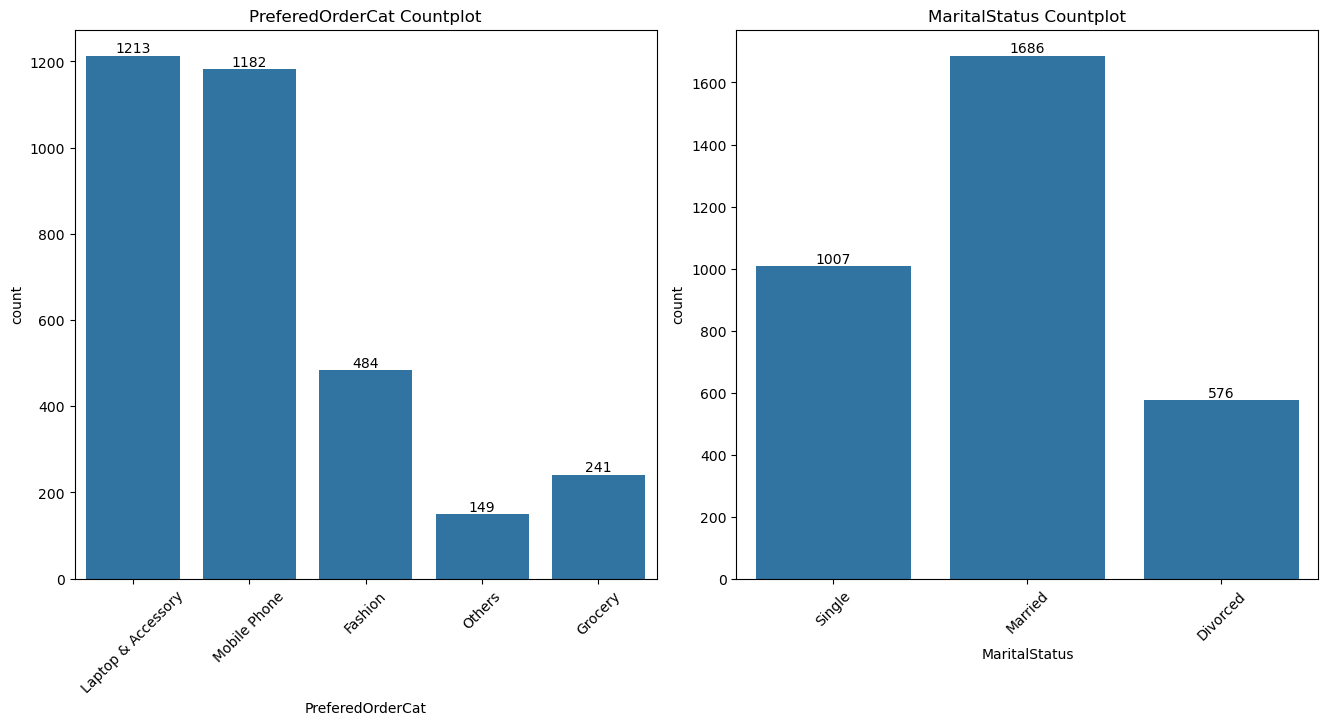

In [26]:
cat_cols = df.select_dtypes(include="object").columns

fig, axes = plt.subplots(3, 3, figsize=(20, 20))
axes = axes.flatten()

for idx, col in enumerate(cat_cols):
    ax = sns.countplot(data=df, x=col, ax=axes[idx])

    # Menampilkan label jumlah di atas setiap bar
    for container in ax.containers:
        ax.bar_label(container, fmt='%d')

    axes[idx].set_title(f"{col} Countplot")
    axes[idx].tick_params(axis='x', rotation=45)

# Hapus subplot yang tidak terpakai
for j in range(len(cat_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

## **3.5 Save Cleaned Dataset**

In [27]:
os.makedirs('../data/cleaned', exist_ok=True)
df.to_csv('../data/cleaned/customer_churn.csv', index=False)

In [28]:
df

,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn,Tenure_missing,WarehouseToHome_missing,DaySinceLastOrder_missing
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0,0,0,0
1,7.0,25.0,4,Mobile Phone,1,Married,2,0,7.0,129.29,0,0,0,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0,0,0,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0,0,0,1
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3264,25.0,15.0,5,Fashion,4,Married,7,0,8.0,249.90,0,0,0,0
3265,26.0,7.0,4,Grocery,1,Married,4,0,9.0,295.99,0,0,0,0
3266,28.0,9.0,5,Fashion,3,Married,8,0,1.0,231.86,0,0,0,0
3267,8.0,7.0,2,Mobile Phone,2,Single,4,0,4.0,157.80,0,0,0,0


# **Section 4. Exploratory Data Analysis (EDA)**


## **4.1 Univariate Analysis**
- Distribusi target
- Distribusi fitur numerik
- Distribusi fitur kategorikal


### **4.1.1 Distribusi Target (`Churn`)**


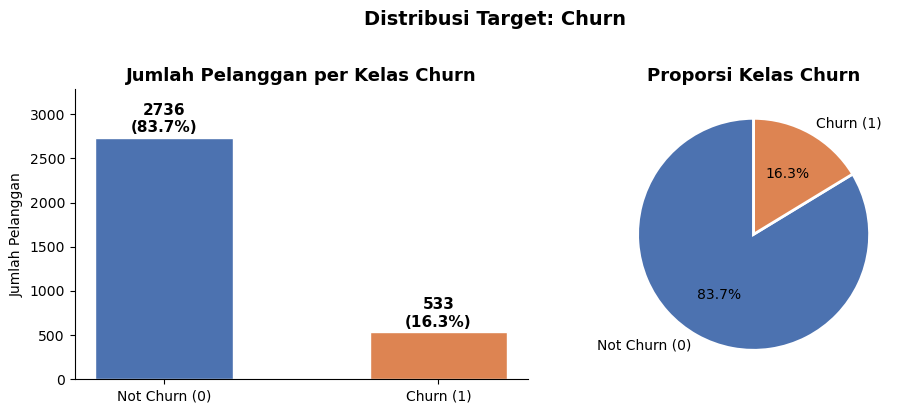

Rasio kelas → Not Churn: 83.7% | Churn: 16.3%
Imbalance ratio (mayoritas:minoritas) ≈ 5.1:1


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

churn_counts = df['Churn'].value_counts()
churn_pct    = df['Churn'].value_counts(normalize=True) * 100
labels       = ['Not Churn (0)', 'Churn (1)']
colors       = ['#4C72B0', '#DD8452']

# Bar chart
axes[0].bar(labels, churn_counts.values, color=colors, edgecolor='white', width=0.5)
for i, (v, p) in enumerate(zip(churn_counts.values, churn_pct.values)):
    axes[0].text(i, v + 30, f'{v}\n({p:.1f}%)', ha='center', va='bottom', fontsize=11, fontweight='bold')
axes[0].set_title('Jumlah Pelanggan per Kelas Churn', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Jumlah Pelanggan')
axes[0].set_ylim(0, churn_counts.max() * 1.2)
axes[0].spines[['top','right']].set_visible(False)

# Pie chart
axes[1].pie(churn_counts.values, labels=labels, colors=colors,
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Proporsi Kelas Churn', fontsize=13, fontweight='bold')

plt.suptitle('Distribusi Target: Churn', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f'Rasio kelas → Not Churn: {churn_pct[0]:.1f}% | Churn: {churn_pct[1]:.1f}%')
print(f'Imbalance ratio (mayoritas:minoritas) ≈ {churn_counts[0]/churn_counts[1]:.1f}:1')

### **4.1.2 Distribusi Fitur Numerik**

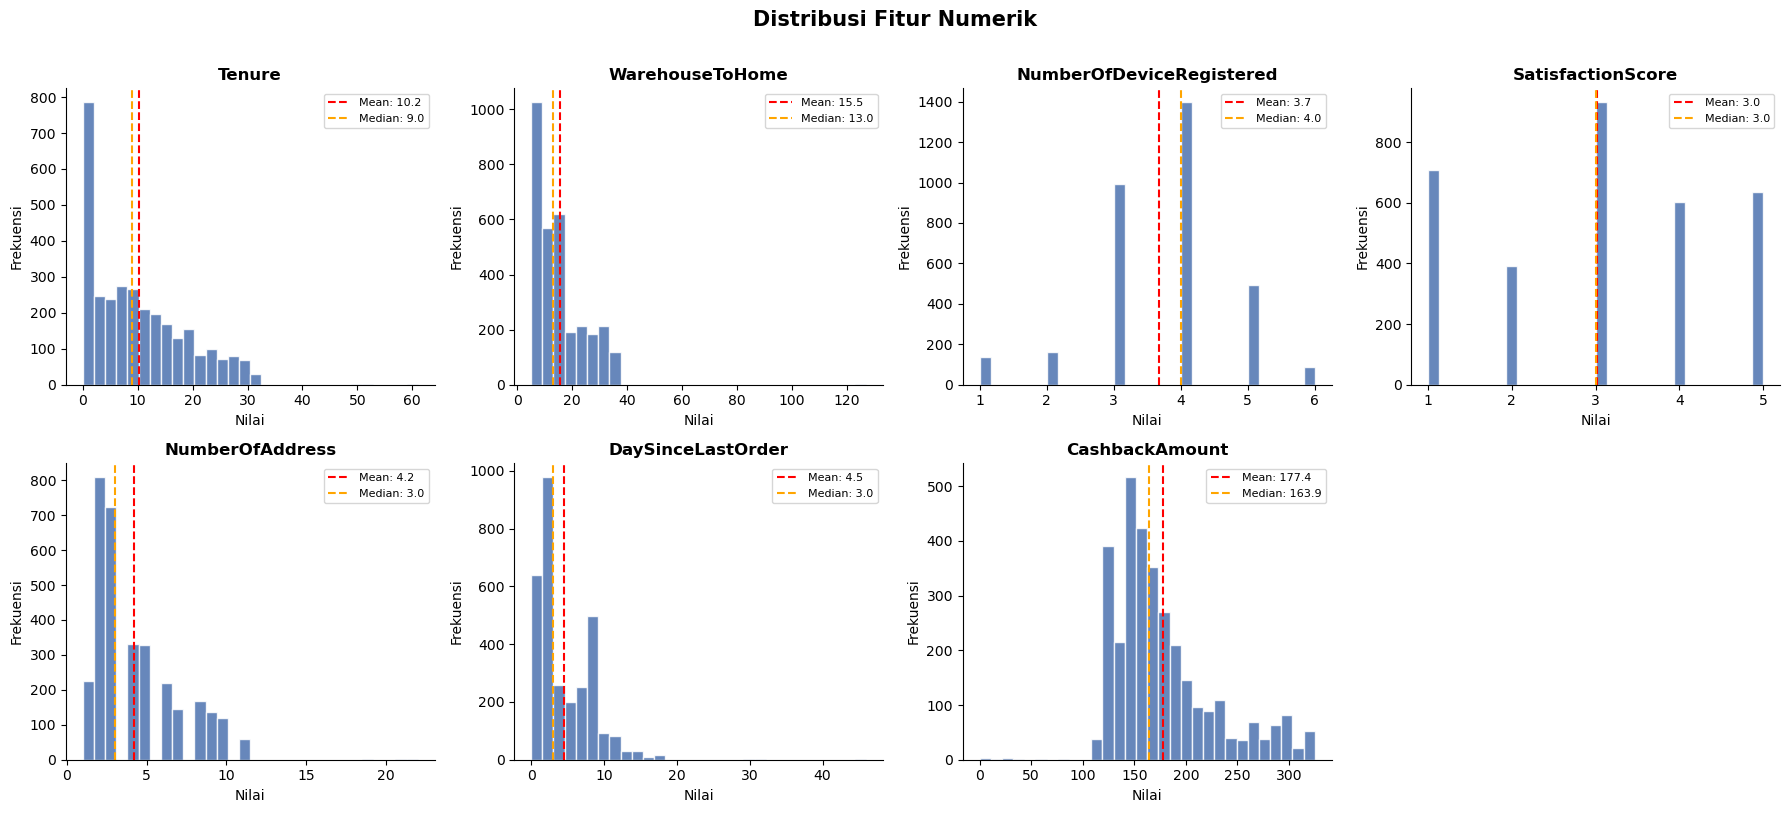

In [30]:
num_cols = ['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered',
            'SatisfactionScore', 'NumberOfAddress', 'DaySinceLastOrder', 'CashbackAmount']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    ax.hist(df[col], bins=30, color='#4C72B0', edgecolor='white', alpha=0.85)
    ax.axvline(df[col].mean(),   color='red',    linestyle='--', linewidth=1.5, label=f'Mean: {df[col].mean():.1f}')
    ax.axvline(df[col].median(), color='orange', linestyle='--', linewidth=1.5, label=f'Median: {df[col].median():.1f}')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('Nilai')
    ax.set_ylabel('Frekuensi')
    ax.legend(fontsize=8)
    ax.spines[['top','right']].set_visible(False)

axes[-1].set_visible(False) 
plt.suptitle('Distribusi Fitur Numerik', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [31]:
skew_df = pd.DataFrame({
    'Mean':     df[num_cols].mean().round(2),
    'Median':   df[num_cols].median().round(2),
    'Std':      df[num_cols].std().round(2),
    'Min':      df[num_cols].min().round(2),
    'Max':      df[num_cols].max().round(2),
    'Skewness': df[num_cols].skew().round(3)
})
display(skew_df)

,Mean,Median,Std,Min,Max,Skewness
Tenure,10.19,9.00,8.65,0.0,61.00,0.810
WarehouseToHome,15.51,13.00,8.57,5.0,127.00,1.527
NumberOfDeviceRegistered,3.68,4.00,1.02,1.0,6.00,-0.406
SatisfactionScore,3.02,3.00,1.40,1.0,5.00,-0.086
NumberOfAddress,4.22,3.00,2.62,1.0,22.00,1.115
DaySinceLastOrder,4.55,3.00,3.70,0.0,46.00,1.430
CashbackAmount,177.44,163.89,49.31,0.0,324.99,1.088


### **4.1.3 Distribusi Fitur Kategorikal**


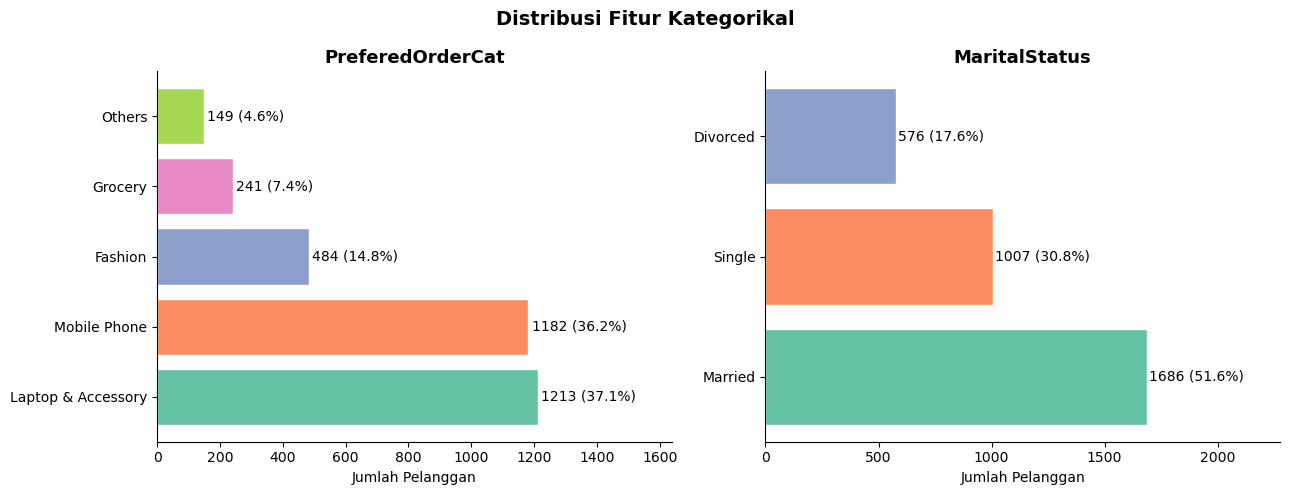

In [32]:
cat_cols = ['PreferedOrderCat', 'MaritalStatus']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col in zip(axes, cat_cols):
    counts = df[col].value_counts()
    pcts   = df[col].value_counts(normalize=True) * 100
    bars   = ax.barh(counts.index, counts.values,
                     color=sns.color_palette('Set2', len(counts)),
                     edgecolor='white')
    for bar, (v, p) in zip(bars, zip(counts.values, pcts.values)):
        ax.text(v + 10, bar.get_y() + bar.get_height()/2,
                f'{v} ({p:.1f}%)', va='center', fontsize=10)
    ax.set_title(col, fontsize=13, fontweight='bold')
    ax.set_xlabel('Jumlah Pelanggan')
    ax.set_xlim(0, counts.max() * 1.35)
    ax.spines[['top','right']].set_visible(False)

plt.suptitle('Distribusi Fitur Kategorikal', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

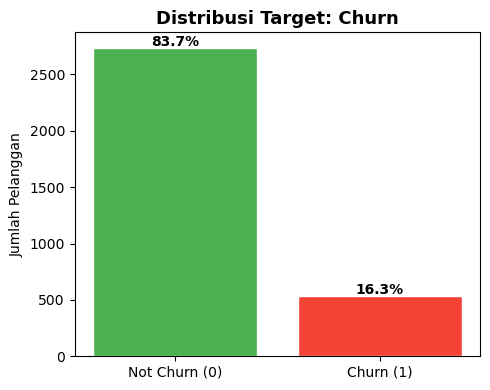

Churn    : 533 (16.3%)
Not Churn: 2,736 (83.7%)


In [33]:
churn_counts = df['Churn'].value_counts()
churn_pct    = df['Churn'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['Not Churn (0)', 'Churn (1)'], churn_counts.values,
              color=['#4CAF50', '#F44336'], edgecolor='white')

for bar, pct in zip(bars, churn_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
            f'{pct:.1f}%', ha='center', fontweight='bold')

ax.set_title('Distribusi Target: Churn', fontsize=13, fontweight='bold')
ax.set_ylabel('Jumlah Pelanggan')
plt.tight_layout()
plt.show()

print(f'Churn    : {churn_counts[1]:,} ({churn_pct[1]:.1f}%)')
print(f'Not Churn: {churn_counts[0]:,} ({churn_pct[0]:.1f}%)')

## **4.2 Bivariate Analysis (terhadap Target)**


### 4.2.1 Numerical Features vs Churn

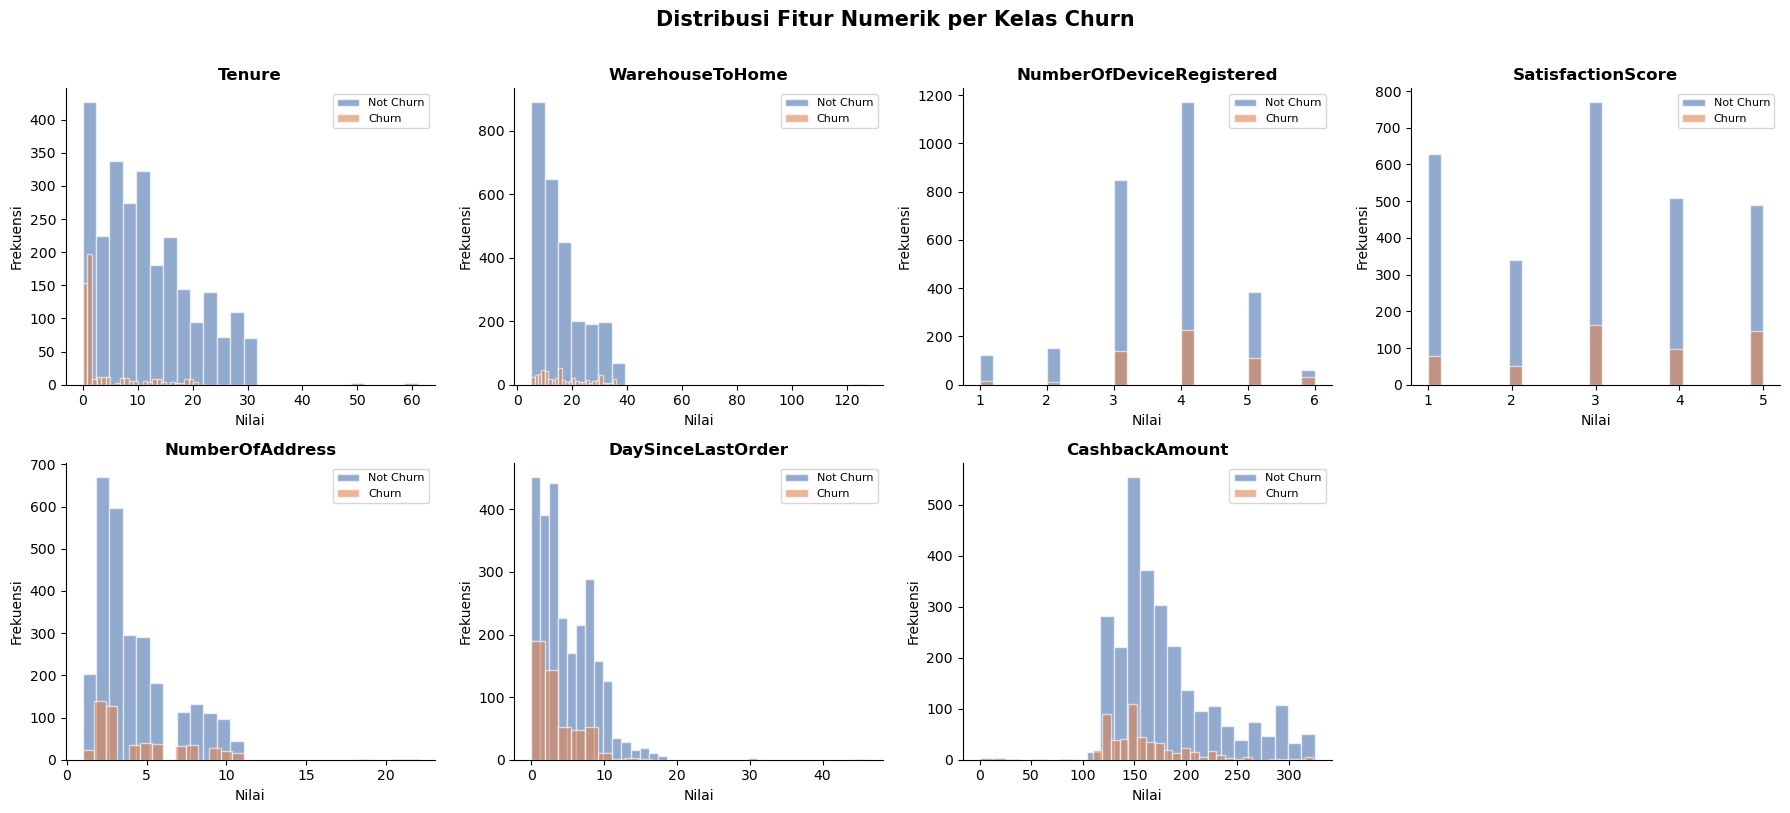

In [34]:
# Distribution of Numeric Features per Churn Class
num_cols = ['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered',
            'SatisfactionScore', 'NumberOfAddress', 'DaySinceLastOrder', 'CashbackAmount']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    for churn_val, label, color in zip([0, 1], ['Not Churn', 'Churn'], ['#4C72B0', '#DD8452']):
        subset = df[df['Churn'] == churn_val][col]
        ax.hist(subset, bins=25, alpha=0.6, label=label, color=color, edgecolor='white')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('Nilai')
    ax.set_ylabel('Frekuensi')
    ax.legend(fontsize=8)
    ax.spines[['top', 'right']].set_visible(False)

axes[-1].set_visible(False)
plt.suptitle('Distribusi Fitur Numerik per Kelas Churn', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

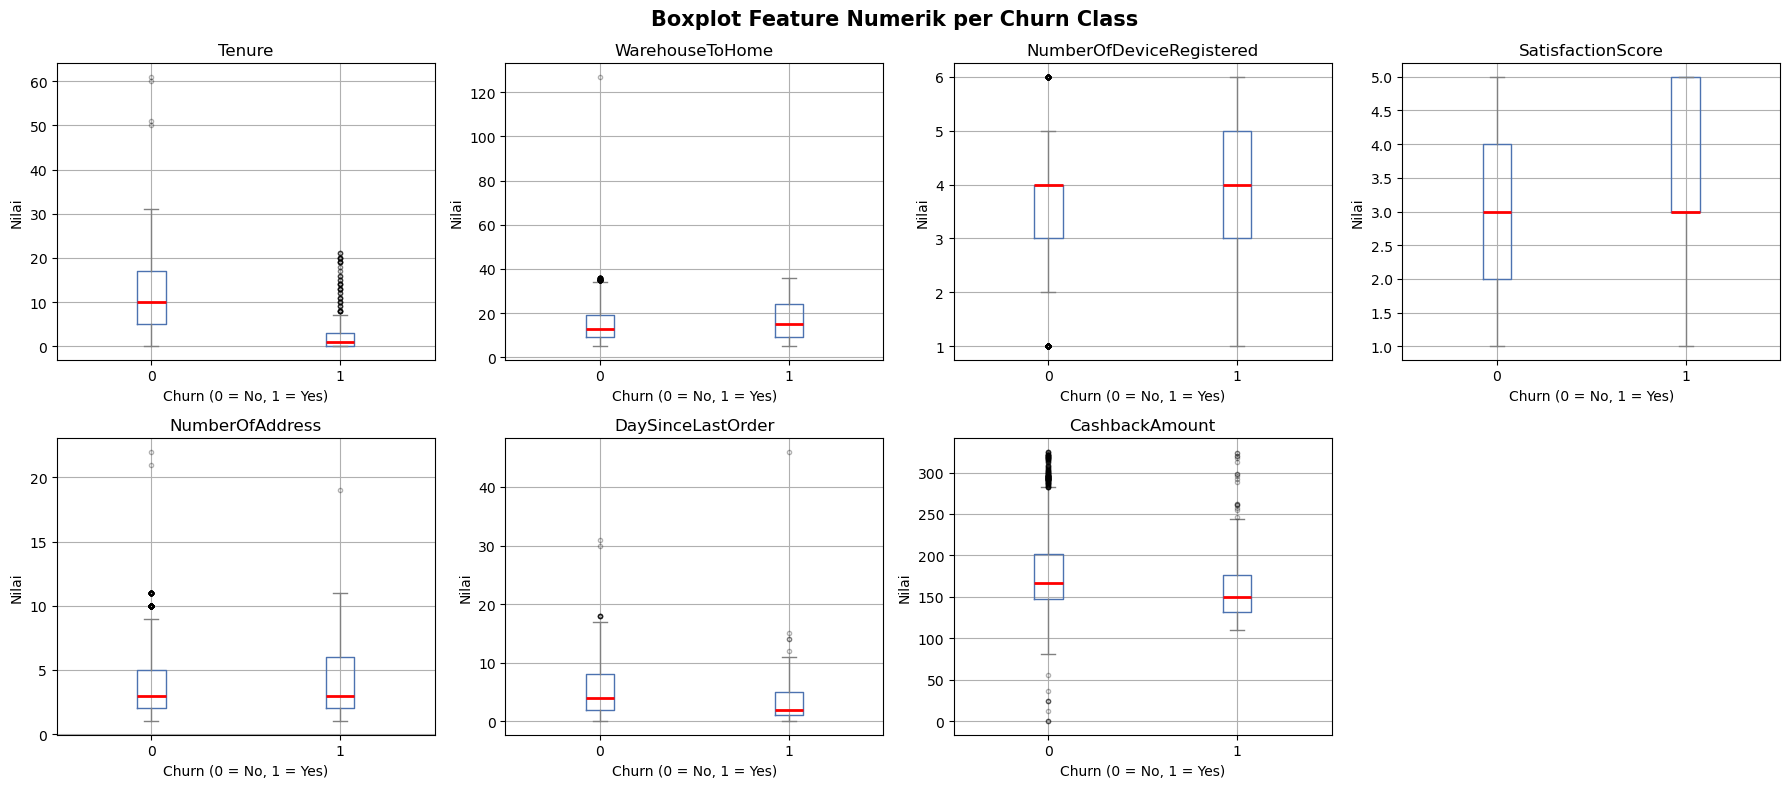

In [35]:
# Boxplot Numeric per Churn Class
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    df.boxplot(column=col, by='Churn', ax=ax,
               boxprops=dict(color='#4C72B0'),
               medianprops=dict(color='red', linewidth=2),
               whiskerprops=dict(color='gray'),
               capprops=dict(color='gray'),
               flierprops=dict(marker='o', color='gray', alpha=0.3, markersize=3))
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('Churn (0 = No, 1 = Yes)')
    ax.set_ylabel('Nilai')
    plt.sca(ax)
    plt.title(col)

axes[-1].set_visible(False)
plt.suptitle('Boxplot Feature Numerik per Churn Class', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### 4.2.2 Categorical Features vs Churn

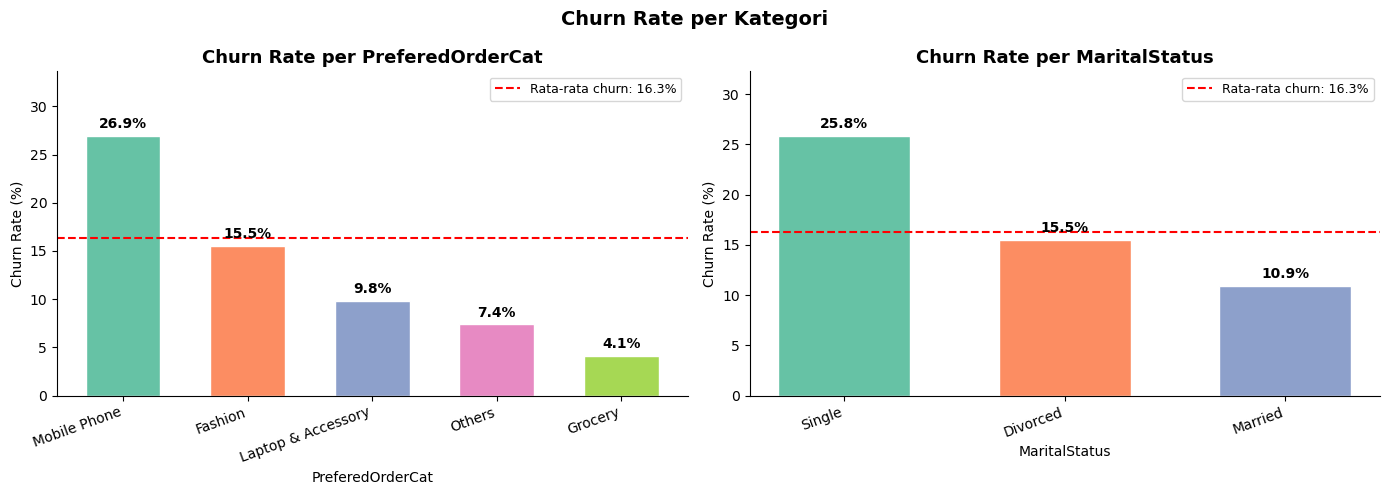

In [36]:
cat_cols = ['PreferedOrderCat', 'MaritalStatus']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, cat_cols):
    churn_rate = df.groupby(col)['Churn'].mean().sort_values(ascending=False) * 100
    bars = ax.bar(churn_rate.index, churn_rate.values,
                  color=sns.color_palette('Set2', len(churn_rate)),
                  edgecolor='white', width=0.6)
    for bar, v in zip(bars, churn_rate.values):
        ax.text(bar.get_x() + bar.get_width()/2, v + 0.5,
                f'{v:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.axhline(df['Churn'].mean() * 100, color='red', linestyle='--',
               linewidth=1.5, label=f'Rata-rata churn: {df["Churn"].mean()*100:.1f}%')
    ax.set_title(f'Churn Rate per {col}', fontsize=13, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Churn Rate (%)')
    ax.set_ylim(0, churn_rate.max() * 1.25)
    ax.legend(fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

plt.suptitle('Churn Rate per Kategori', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

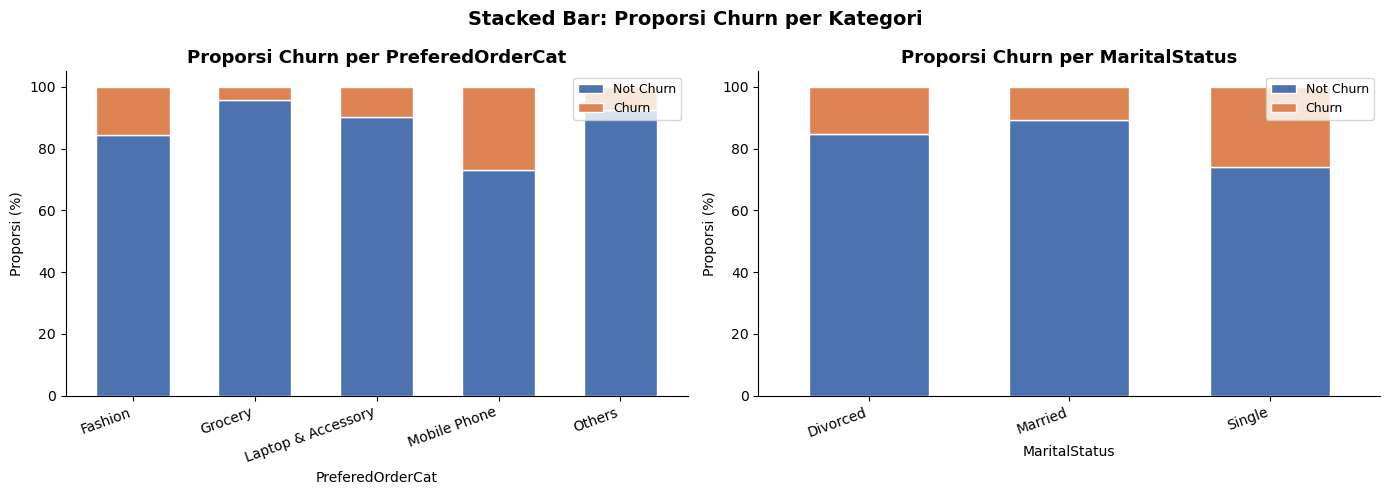

In [37]:
# Stacked Bar Churn per Category
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, cat_cols):
    ct = pd.crosstab(df[col], df['Churn'], normalize='index') * 100
    ct.columns = ['Not Churn', 'Churn']
    ct.plot(kind='bar', stacked=True, ax=ax,
            color=['#4C72B0', '#DD8452'], edgecolor='white', width=0.6)
    ax.set_title(f'Proporsi Churn per {col}', fontsize=13, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Proporsi (%)')
    ax.legend(loc='upper right', fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

plt.suptitle('Stacked Bar: Proporsi Churn per Kategori', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## **4.3 Correlation & Multicollinearity Check**


### 4.3.1 Correlation Heatmap

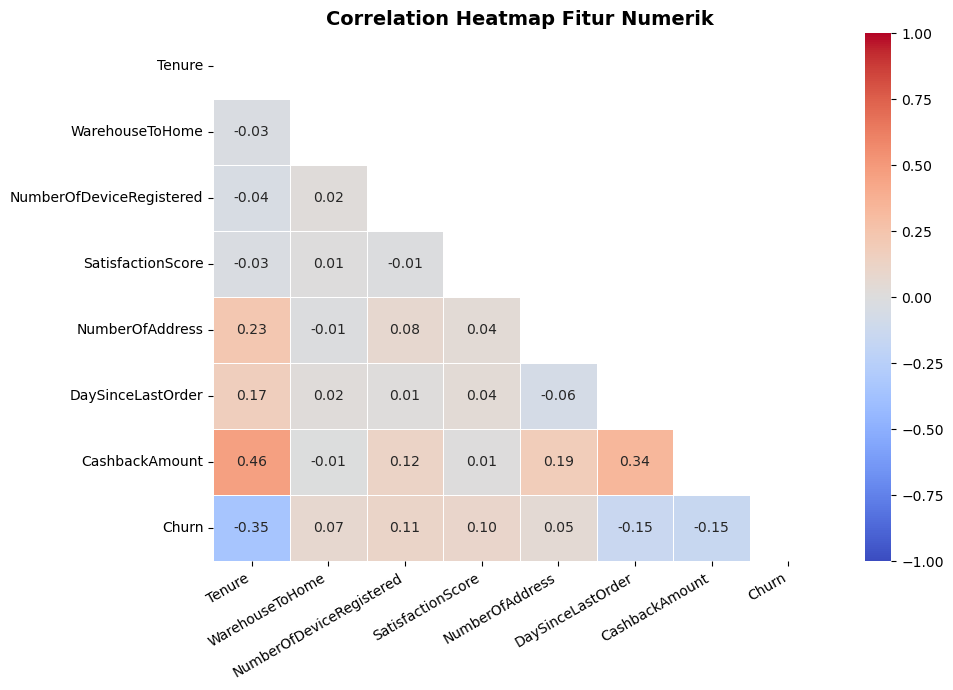

In [38]:
plt.figure(figsize=(10, 7))

corr_matrix = df[num_cols + ['Churn']].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor='white',
            annot_kws={'size': 10})

plt.title('Correlation Heatmap Fitur Numerik', fontsize=14, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

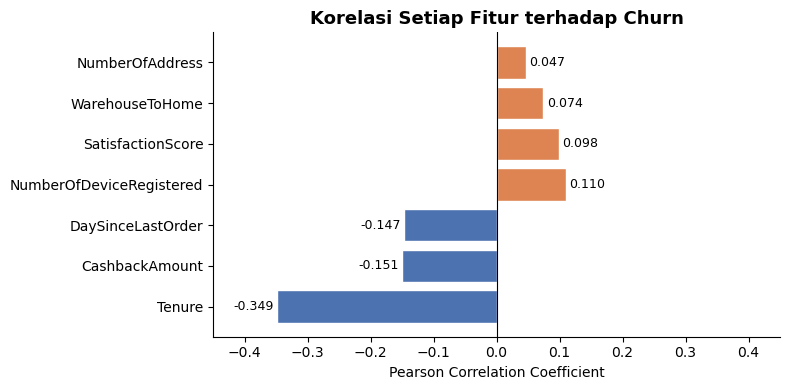

In [39]:
# Sort Highest Correlation Towards Churn
corr_with_churn = corr_matrix['Churn'].drop('Churn').sort_values(key=abs, ascending=False)

plt.figure(figsize=(8, 4))
colors = ['#DD8452' if v > 0 else '#4C72B0' for v in corr_with_churn.values]
bars = plt.barh(corr_with_churn.index, corr_with_churn.values, color=colors, edgecolor='white')
plt.axvline(0, color='black', linewidth=0.8)
for bar, v in zip(bars, corr_with_churn.values):
    plt.text(v + (0.005 if v >= 0 else -0.005), bar.get_y() + bar.get_height()/2,
             f'{v:.3f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9)
plt.title('Korelasi Setiap Fitur terhadap Churn', fontsize=13, fontweight='bold')
plt.xlabel('Pearson Correlation Coefficient')
plt.xlim(-0.45, 0.45)
plt.gca().spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### 4.3.2 Pairplot Selected Feature vs Churn

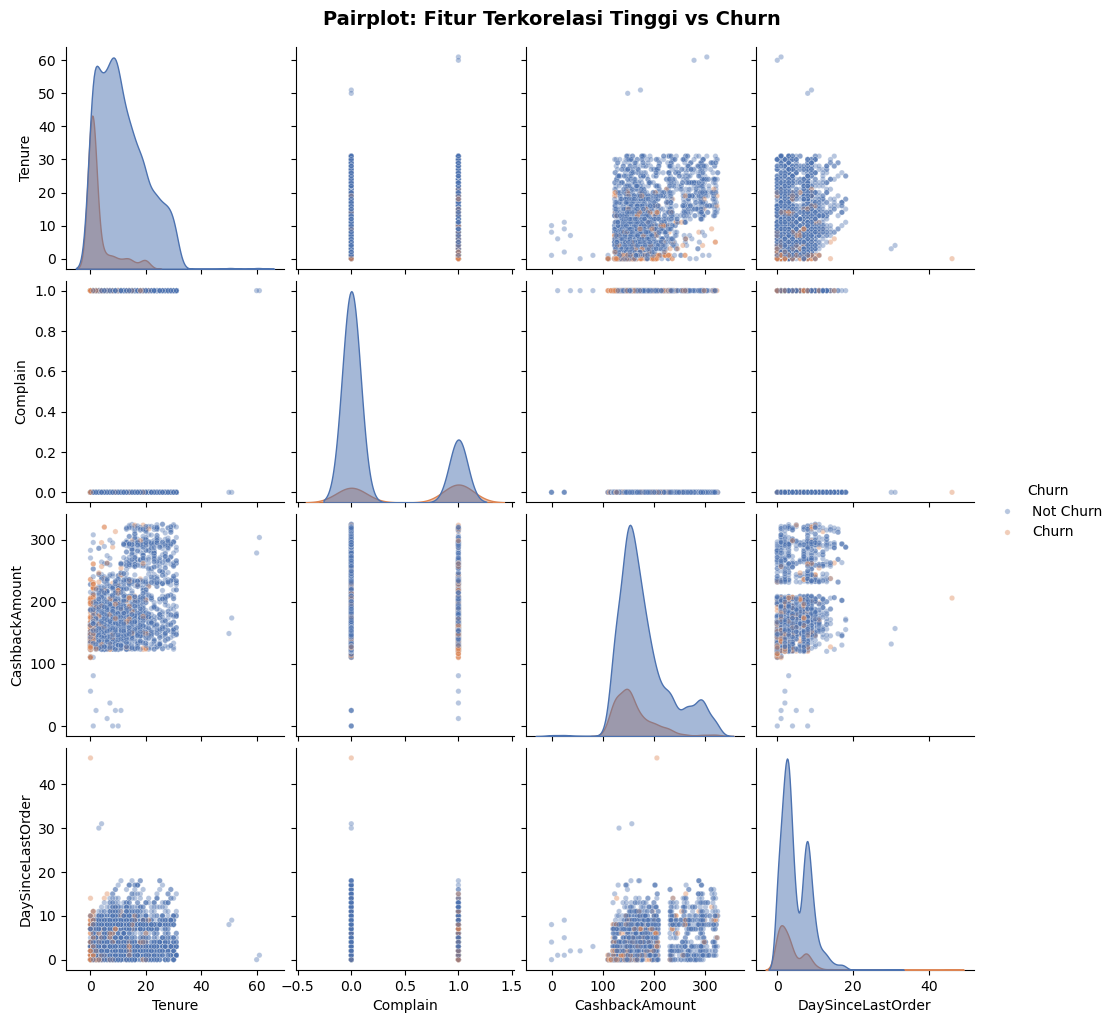

In [40]:
top_features = ['Tenure', 'Complain', 'CashbackAmount', 'DaySinceLastOrder', 'Churn']

pair_df = df[top_features].copy()
pair_df['Churn'] = pair_df['Churn'].map({0: 'Not Churn', 1: 'Churn'})

g = sns.pairplot(pair_df, hue='Churn', palette={'Not Churn': '#4C72B0', 'Churn': '#DD8452'},
                 diag_kind='kde', plot_kws={'alpha': 0.4, 's': 15},
                 diag_kws={'fill': True, 'alpha': 0.5})

g.figure.suptitle('Pairplot: Fitur Terkorelasi Tinggi vs Churn',
                  fontsize=14, fontweight='bold', y=1.02)
plt.show()

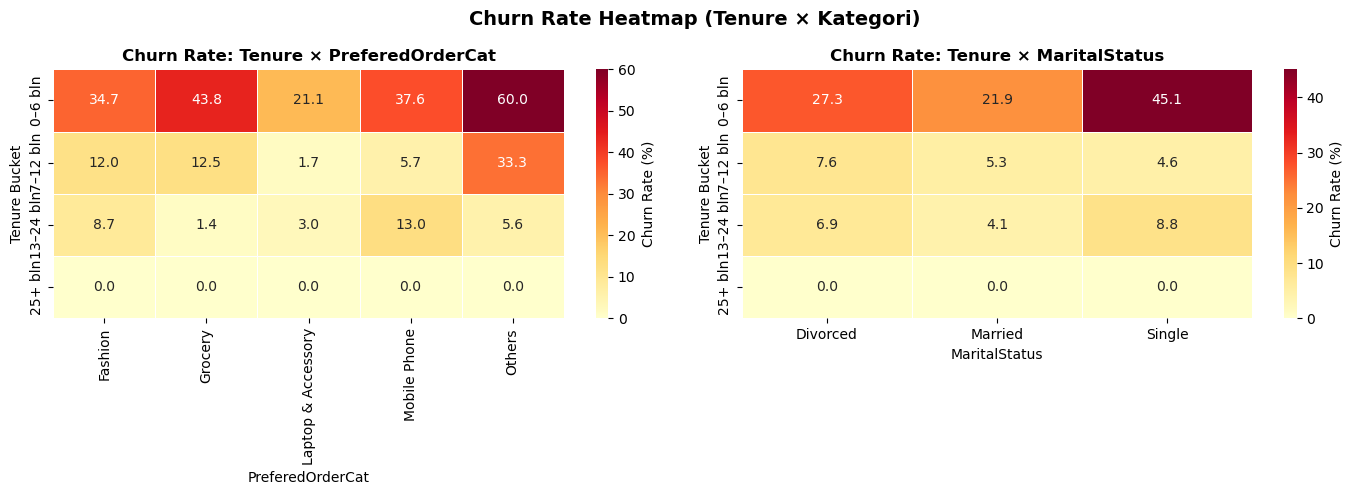

In [41]:
# Create Tenue Bucket
df['Tenure_bucket'] = pd.cut(df['Tenure'], bins=[0, 6, 12, 24, 62],
                              labels=['0–6 bln', '7–12 bln', '13–24 bln', '25+ bln'],
                              include_lowest=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col in zip(axes, ['PreferedOrderCat', 'MaritalStatus']):
    pivot = df.pivot_table(values='Churn', index='Tenure_bucket',
                           columns=col, aggfunc='mean') * 100
    sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd',
                linewidths=0.5, linecolor='white', ax=ax,
                cbar_kws={'label': 'Churn Rate (%)'})
    ax.set_title(f'Churn Rate: Tenure × {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Tenure Bucket')

plt.suptitle('Churn Rate Heatmap (Tenure × Kategori)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Delete Helper Column Once Done
df.drop(columns=['Tenure_bucket'], inplace=True)

# **Section 5. Data Preparation**


## **5.1 Initialization**
- Initialization function
- Define Feature and Target


In [42]:
# Define feature & target
feature = df.drop(columns='Churn')
target = df['Churn']

## **5.2 Constructing `Training` and `Testing` Data (from `Seen` Dataset)**


In [43]:
# TODO: Split dataset into training and testing set
x_train, x_test, y_train, y_test = train_test_split(
    feature,
    target,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=target
)

# Reset index
x_train.reset_index(inplace=True, drop=True)
x_test.reset_index(inplace=True, drop=True)
y_train.reset_index(inplace=True, drop=True)
y_test.reset_index(inplace=True, drop=True)

# Save training and testing datasets
train_df = pd.concat([x_train, y_train], axis=1)
test_df = pd.concat([x_test, y_test], axis=1)

train_df.to_csv('../data/processed/data-train.csv', index=False)
test_df.to_csv('../data/processed/data-test.csv', index=False)

## **5.3 Handling Imbalanced Data**

In [44]:
# Cek distribusi kelas
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
0    2736
1     533
Name: count, dtype: int64
Churn
0    83.69532
1    16.30468
Name: proportion, dtype: float64


> Berdasarkan hasil eksplorasi data, ditemukan distribusi kelas target yang tidak seimbang (*imbalanced*), dengan proporsi Churn = 0 sebesar 83.7% dan Churn = 1 sebesar 16.3%. Ketimpangan distribusi ini berpotensi menyebabkan model bias terhadap kelas mayoritas dan kurang sensitif dalam mendeteksi kelas minoritas (pelanggan yang benar-benar churn). Oleh karena itu, diterapkan teknik *oversampling* SMOTE (*Synthetic Minority Oversampling Technique*) untuk menyeimbangkan distribusi kelas pada data latih.

## **5.4 Data Transformation (Feature Engineering)**


In [45]:
# Numerik yang pakai median GLOBAL -> imputasi + scaling
NUMERIC_COLS = [
    "WarehouseToHome",
    "NumberOfDeviceRegistered",
    "NumberOfAddress",
    "DaySinceLastOrder",
    "CashbackAmount",
]

# Numerik yang pakai median PER-KELOMPOK (PreferedOrderCat)
GROUPED_MEDIAN_COL = "Tenure"
GROUP_COL = "PreferedOrderCat"

# Kategorik berbentuk karakter/string -> One-Hot Encoding
CATEGORICAL_CHAR_COLS = [
    "PreferedOrderCat",
    "MaritalStatus",
]

# Kategorik yang sudah berbentuk angka (0/1) -> dibiarkan (tidak di-scale/encode)
CATEGORICAL_NUM_COLS = [
    "SatisfactionScore",
    "Complain",
]

In [46]:
# Pipeline imputasi SAJA (tanpa scaling/encoding) - harus jalan sebelum Winsorizer
imputation_pipeline = ColumnTransformer(
    transformers=[
        ("numeric_impute", SimpleImputer(strategy="median"), NUMERIC_COLS),
        ("tenure_impute", GroupedMedianImputer(group_col=GROUP_COL, target_col=GROUPED_MEDIAN_COL), [GROUP_COL, GROUPED_MEDIAN_COL]),
        ("cat_char_impute", SimpleImputer(strategy="most_frequent"), CATEGORICAL_CHAR_COLS),
        ("cat_num_impute", SimpleImputer(strategy="most_frequent"), CATEGORICAL_NUM_COLS),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

# Preprocessing SETELAH imputasi: scaling + encoding
preprocessor = ColumnTransformer(
    transformers=[
        ("scale_numeric", RobustScaler(), NUMERIC_COLS + [GROUPED_MEDIAN_COL]),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_CHAR_COLS),
    ],
    remainder="passthrough"  
)

# Base model pipeline with resampling
model_res_pipeline = ImbPipeline(steps=[
    ('imputation', imputation_pipeline),
    ('outlier_capping', Winsorizer(variables=NUMERIC_COLS + [GROUPED_MEDIAN_COL], capping_method='iqr', tail='both', fold=1.5)),
    ('feature_engineering', preprocessor),
    ('feature_selection', SelectKBest()),
    ('feature_resampling', SMOTE(random_state=RANDOM_STATE)),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE))
])
model_res_pipeline.fit(x_train, y_train)

,steps,"[('imputation', ...), ('outlier_capping', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric_impute', ...), ('tenure_impute', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


## **5.5 Feature Selection**


In [47]:
# pastikan pipeline sudah di-fit dulu
# model_res_pipeline.fit(X_train, y_train)

# 1. Ambil step yang relevan dari pipeline
preprocessor_fitted = model_res_pipeline.named_steps['feature_engineering']
selector_fitted = model_res_pipeline.named_steps['feature_selection']

# 2. Ambil nama fitur hasil ColumnTransformer (urutan sesuai urutan transformer di dalamnya)
feature_names_after_preprocessing = preprocessor_fitted.get_feature_names_out()

# 3. Ambil mask boolean fitur yang terpilih dari SelectKBest
selected_mask = selector_fitted.get_support()

# 4. Gabungkan -> nama fitur yang lolos seleksi
selected_features = feature_names_after_preprocessing[selected_mask]

print(f"Jumlah fitur sebelum seleksi : {len(feature_names_after_preprocessing)}")
print(f"Jumlah fitur setelah seleksi : {len(selected_features)}")
print(selected_features)

Jumlah fitur sebelum seleksi : 16
Jumlah fitur setelah seleksi : 10
['scale_numeric__NumberOfDeviceRegistered'
 'scale_numeric__DaySinceLastOrder' 'scale_numeric__CashbackAmount'
 'scale_numeric__Tenure' 'onehot__PreferedOrderCat_Laptop & Accessory'
 'onehot__PreferedOrderCat_Mobile Phone' 'onehot__MaritalStatus_Married'
 'onehot__MaritalStatus_Single' 'remainder__SatisfactionScore'
 'remainder__Complain']


## **5.6 Overview**

Tahapan data preparation yang telah dilakukan meliputi:

1. **Outlier Capping (Winsorizer)** — dilakukan pada kolom numerik (`NUMERIC_COLS`) untuk membatasi pengaruh nilai ekstrem tanpa menghapus baris data, guna menjaga ukuran sampel tetap utuh.
2. **Feature Engineering (ColumnTransformer)**:
   - Kolom numerik diimputasi (median) dan di-scaling menggunakan `RobustScaler` agar tahan terhadap outlier residual.
   - Kolom kategorikal string (`CATEGORICAL_CHAR_COLS`) diimputasi (`constant: unknown`) dan di-encode menggunakan One-Hot Encoding.
   - Kolom kategorikal biner (`CATEGORICAL_NUM_COLS`) diimputasi (`most_frequent`) tanpa transformasi lebih lanjut.
3. **Feature Selection (SelectKBest)** — dilakukan seleksi fitur untuk mengurangi dimensi dan menghilangkan fitur yang kurang informatif terhadap target (`Churn`).
4. **Resampling (SMOTE)** — diterapkan pada pipeline `model_res_pipeline` untuk menangani ketidakseimbangan kelas pada target, dengan sintesis data pada kelas minoritas.

In [48]:
# 1. Sebelum preprocessing
rows_before, feat_before = x_train.shape

# 2. Setelah encoding (sebelum seleksi) -> replay imputation -> capping -> feature_engineering
x_train_imputed = model_res_pipeline.named_steps['imputation'].transform(x_train)
x_train_capped  = model_res_pipeline.named_steps['outlier_capping'].transform(x_train_imputed)
x_train_encoded = model_res_pipeline.named_steps['feature_engineering'].transform(x_train_capped)
rows_after_encoding, feat_after_encoding = x_train_encoded.shape

# 3. Setelah feature selection
x_train_selected = model_res_pipeline.named_steps['feature_selection'].transform(x_train_encoded)
rows_after_selection, feat_after_selection = x_train_selected.shape

# 4. Setelah resampling (train saja) -> SMOTE difit ulang di luar pipeline
x_train_resampled, y_train_resampled = model_res_pipeline.named_steps['feature_resampling'].fit_resample(
    x_train_selected, y_train
)
rows_after_resampling, feat_after_resampling = x_train_resampled.shape

# Distribusi target sebelum & sesudah SMOTE
dist_before = y_train.value_counts().sort_index()
dist_after  = pd.Series(y_train_resampled).value_counts().sort_index()

print("Ringkasan bentuk data:")
print(f"Sebelum preprocessing               : {rows_before} baris, {feat_before} fitur")
print(f"Setelah encoding (sebelum seleksi)   : {rows_after_encoding} baris, {feat_after_encoding} fitur")
print(f"Setelah feature selection            : {rows_after_selection} baris, {feat_after_selection} fitur")
print(f"Setelah resampling (train saja)      : {rows_after_resampling} baris, {feat_after_resampling} fitur")

print("\nDistribusi target:")
print(f"0 (No)  : sebelum={dist_before[0]}, sesudah={dist_after[0]}")
print(f"1 (Yes) : sebelum={dist_before[1]}, sesudah={dist_after[1]}")

Ringkasan bentuk data:
Sebelum preprocessing               : 2615 baris, 13 fitur
Setelah encoding (sebelum seleksi)   : 2615 baris, 16 fitur
Setelah feature selection            : 2615 baris, 10 fitur
Setelah resampling (train saja)      : 4378 baris, 10 fitur

Distribusi target:
0 (No)  : sebelum=2189, sesudah=2189
1 (Yes) : sebelum=426, sesudah=2189


**Ringkasan bentuk data akhir:**

| Tahap | Jumlah Baris | Jumlah Fitur |
| ----- | ------------ | ------------ |
| Sebelum preprocessing | 2615 | 13 |
| Setelah encoding (sebelum seleksi) | 2615 | 16 |
| Setelah feature selection | 2615 | 10 |
| Setelah resampling (train saja)  | 4378 | 10 |

Distribusi target sebelum dan sesudah resampling:

| Kelas | Sebelum SMOTE | Sesudah SMOTE |
| ----- | ------------- | ------------- |
| 0 (No) | 2189 | 2189 |
| 1 (Yes) | 2189 | 2189 |

# **Section 6. Model Development**


## **6.1 Initialization**
- Create Custom Metrics
- Define Cross-Validation Strategy

In [49]:
# CV Strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Custom F2 scorer
f2_scorer = make_scorer(fbeta_score, beta=2, pos_label=1)

# Scorer dict — ROC-AUC dihitung manual terpisah karena ImbPipeline
# tidak kompatibel dengan needs_proba scorer di cross_validate
scorers = {
    'recall':    make_scorer(recall_score,    pos_label=1),
    'precision': make_scorer(precision_score, pos_label=1, zero_division=0),
    'f1':        make_scorer(f1_score,        pos_label=1),
    'f2':        f2_scorer,
}

## **6.2 Developing the Model**


In [50]:
# TODO: Inisialisasi model
logreg = LogisticRegression(random_state=RANDOM_STATE)
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)
knn = KNeighborsClassifier()
rf = RandomForestClassifier(random_state=RANDOM_STATE)
bagging = BaggingClassifier(estimator=logreg, random_state=RANDOM_STATE)
xgb = XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric='logloss',
    verbosity=0
)
ab = AdaBoostClassifier(random_state=RANDOM_STATE, estimator=DecisionTreeClassifier())
gb = GradientBoostingClassifier(random_state=RANDOM_STATE)
lgbm = lightgbm.LGBMClassifier()
# TODO: Model initialization
voting = VotingClassifier(estimators=[('knn', knn), ('dt', dt), ('logreg', logreg)], voting='soft')
stacking = StackingClassifier(
    estimators=[('knn', knn), ('dt', dt)],
    final_estimator=logreg
)

In [51]:
# Kandidat model
candidates = {
    'Logistic Regression': logreg,
    'KNN':                 knn,
    'Decision Tree':       dt,
    'Random Forest':       rf,
    'Bagging':             bagging,
    'XGBoost':             xgb,
    'AdaBoost':            ab,
    'GradientBoost':       gb,
    'LightGBM':            lgbm,
    'Voting':              voting,
    'Stacking':            stacking
}

## **6.3 Model Benchmarking**


In [52]:
# With resampling
benchmark_models(
    model_res_pipeline, 
    candidates, 
    x_train, 
    y_train, 
    scoring='recall',
    cv=5, 
    random_state=RANDOM_STATE
)

[LightGBM] [Info] Number of positive: 1751, number of negative: 1751
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000326 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1476
[LightGBM] [Info] Number of data points in the train set: 3502, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 1751, number of negative: 1751
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000298 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1299
[LightGBM] [Info] Number of data points in the train set: 3502, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Number of positive: 1751, number of negative: 1751
[LightGBM] [Info] Auto-choosing col-wise multi-threading, t

,name,mean_train_score,std_train_score,mean_test_score,std_test_score
0,Logistic Regression,0.801641,0.005836,0.802791,0.009301
1,Bagging,0.802815,0.003968,0.795732,0.012615
2,KNN,0.980050,0.006524,0.751190,0.042887
3,Voting,0.998240,0.001437,0.723092,0.062062
4,GradientBoost,0.761154,0.007883,0.680848,0.032503
5,Random Forest,0.999413,0.001173,0.654993,0.029471
6,XGBoost,0.987090,0.007086,0.650315,0.033467
7,AdaBoost,1.000000,0.000000,0.636142,0.030725
8,LightGBM,0.932512,0.009458,0.624569,0.074565
9,Stacking,0.985915,0.005982,0.612750,0.064358


## **6.4 Tune Model**


### 6.4.1 Logistic Regression Tuning

In [53]:
# TODO: Save best logreg
lr_model = clone(model_res_pipeline.set_params(classifier=logreg))

In [54]:
lr_param_grid = {
    'classifier__C':            [0.01, 0.1, 1, 10, 100],
    'classifier__penalty':      ['l1', 'l2'],
    'classifier__solver':       ['liblinear', 'saga'],
    'classifier__max_iter':     [100, 200, 500, 1000],
    'feature_selection__k':     [6, 8, 10, 12, 'all'],
}

lr_tuning = GridSearchCV(
    estimator=lr_model,
    param_grid=lr_param_grid,
    scoring=f2_scorer,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
    verbose=1
)
lr_tuning.fit(x_train, y_train)

print(f"\nBest F2 LR : {lr_tuning.best_score_:.4f}")
print(f"Best params     : {lr_tuning.best_params_}")
best_lr = lr_tuning.best_estimator_

Fitting 5 folds for each of 400 candidates, totalling 2000 fits

Best F2 LR : 0.6876
Best params     : {'classifier__C': 100, 'classifier__max_iter': 100, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear', 'feature_selection__k': 'all'}


#### Evaluation Before VS After Tuning

In [55]:
# Model before tuning
base_logreg = clone(model_res_pipeline.set_params(classifier=logreg))
base_logreg.fit(x_train, y_train)

# Model after tuning
tunned_logreg = lr_tuning.best_estimator_
tunned_logreg.fit(x_train, y_train)

,steps,"[('imputation', ...), ('outlier_capping', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric_impute', ...), ('tenure_impute', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [56]:
# TODO: Model prediction (before tuning)
y_train_pred_logreg = base_logreg.predict(x_train)
y_test_pred_logreg = base_logreg.predict(x_test)

print('Base model Logistic Regression')
print(f'Model performance (train): {recall_score(y_train, y_train_pred_logreg):.2%}')
print(f'Model performance (test): {recall_score(y_test, y_test_pred_logreg):.2%}')

Base model Logistic Regression
Model performance (train): 80.05%
Model performance (test): 82.24%


In [57]:
# TODO: Model prediction (after tuning)
y_train_pred_logreg = tunned_logreg.predict(x_train)
y_test_pred_logreg = tunned_logreg.predict(x_test)

print('Base model Logistic Regression')
print(f'Model performance (train): {recall_score(y_train, y_train_pred_logreg):.2%}')
print(f'Model performance (test): {recall_score(y_test, y_test_pred_logreg):.2%}')

Base model Logistic Regression
Model performance (train): 81.46%
Model performance (test): 85.05%


### 6.4.2 GradientBoost Tuning

In [58]:
# TODO: Save best GradientBoost
gb_model = clone(model_res_pipeline.set_params(classifier=gb))

In [59]:
gb_param_grid = {
    'classifier__n_estimators':  [50, 100, 200, 300, 500],
    'classifier__learning_rate': [0.001, 0.01, 0.05, 0.1, 0.3, 0.5, 1.0],
    'classifier__max_depth':     [2, 3, 4, 5],
    'classifier__subsample':     [0.6, 0.7, 0.8, 1.0],
    'feature_selection__k':      [6, 8, 10, 12, 'all']   
}

gb_tuning = GridSearchCV(
    estimator=gb_model,
    param_grid=gb_param_grid,
    scoring=f2_scorer,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
    verbose=1
)
gb_tuning.fit(x_train, y_train)

print(f"\nBest GB F2  : {gb_tuning.best_score_:.4f}")
print(f"Best params : {gb_tuning.best_params_}")
best_gb   = gb_tuning.best_estimator_

Fitting 5 folds for each of 2800 candidates, totalling 14000 fits

Best GB F2  : 0.7181
Best params : {'classifier__learning_rate': 0.3, 'classifier__max_depth': 4, 'classifier__n_estimators': 500, 'classifier__subsample': 1.0, 'feature_selection__k': 'all'}


#### Evaluation Before VS After Tuning

In [60]:
# Model before tuning
base_gb = clone(model_res_pipeline.set_params(classifier=gb))
base_gb.fit(x_train, y_train)

# Model after tuning
tunned_gb = gb_tuning.best_estimator_
tunned_gb.fit(x_train, y_train)

,steps,"[('imputation', ...), ('outlier_capping', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric_impute', ...), ('tenure_impute', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [61]:
# TODO: Model prediction (before tuning)
y_train_pred_gb = base_gb.predict(x_train)
y_test_pred_gb  = base_gb.predict(x_test)

print('Base model GradientBoost')
print(f'Model performance (train): {recall_score(y_train, y_train_pred_gb):.2%}')
print(f'Model performance (test) : {recall_score(y_test, y_test_pred_gb):.2%}')

Base model GradientBoost
Model performance (train): 75.59%
Model performance (test) : 75.70%


In [62]:
# TODO: Model prediction (after tuning)
y_train_pred_gb = tunned_gb.predict(x_train)
y_test_pred_gb  = tunned_gb.predict(x_test)

print('Tuned model GradientBoost (After Tuning)')
print(f'Model performance (train): {recall_score(y_train, y_train_pred_gb):.2%}')
print(f'Model performance (test) : {recall_score(y_test, y_test_pred_gb):.2%}')

Tuned model GradientBoost (After Tuning)
Model performance (train): 100.00%
Model performance (test) : 73.83%


### 6.4.3 Bagging Tuning

In [63]:
# Save best bagging
bagging_model = clone(model_res_pipeline.set_params(classifier=bagging))

In [64]:
bagging_param_grid = {
    'classifier__n_estimators':         [10, 25, 50, 100, 150, 200],
    'classifier__max_samples':          [0.5, 0.6, 0.7, 0.8, 1.0],
    'classifier__max_features':         [0.5, 0.6, 0.7, 0.8, 1.0],
    'classifier__bootstrap':            [True, False],
    'classifier__bootstrap_features':   [True, False],
    'feature_selection__k':             [6, 8, 10, 12, 'all'],
}

bagging_tuning = GridSearchCV(
    estimator=bagging_model,
    param_grid=bagging_param_grid,
    scoring=f2_scorer,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
    verbose=1
)
bagging_tuning.fit(x_train, y_train)

print(f"\nBest F2 Bagging : {bagging_tuning.best_score_:.4f}")
print(f"Best params         : {bagging_tuning.best_params_}")
best_bagging = bagging_tuning.best_estimator_

Fitting 5 folds for each of 3000 candidates, totalling 15000 fits

Best F2 Bagging : 0.6894
Best params         : {'classifier__bootstrap': False, 'classifier__bootstrap_features': False, 'classifier__max_features': 0.5, 'classifier__max_samples': 0.7, 'classifier__n_estimators': 100, 'feature_selection__k': 'all'}


#### Evaluation Before VS After Tuning

In [65]:
# Model before tuning
base_bagging = clone(model_res_pipeline.set_params(classifier=bagging))
base_bagging.fit(x_train, y_train)

# Model after tuning
tunned_bagging = bagging_tuning.best_estimator_
tunned_bagging.fit(x_train, y_train)

,steps,"[('imputation', ...), ('outlier_capping', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric_impute', ...), ('tenure_impute', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [66]:
# Before tuning
y_train_pred_bagging = base_bagging.predict(x_train)
y_test_pred_bagging  = base_bagging.predict(x_test)

print('Base model Bagging')
print(f'Model performance (train): {recall_score(y_train, y_train_pred_bagging):.2%}')
print(f'Model performance (test) : {recall_score(y_test, y_test_pred_bagging):.2%}')

Base model Bagging
Model performance (train): 80.28%
Model performance (test) : 82.24%


In [67]:
# After tuning
y_train_pred_bagging = tunned_bagging.predict(x_train)
y_test_pred_bagging  = tunned_bagging.predict(x_test)

print('Tuned model Bagging')
print(f'Model performance (train): {recall_score(y_train, y_train_pred_bagging):.2%}')
print(f'Model performance (test) : {recall_score(y_test, y_test_pred_bagging):.2%}')

Tuned model Bagging
Model performance (train): 81.92%
Model performance (test) : 86.92%


### 6.4.4 Comparing Tuning Results

In [88]:
lr_model.fit(x_train, y_train)
gb_model.fit(x_train, y_train)
bagging_model.fit(x_train, y_train)

base_rows = []

for name, model in [
    ('Logistic Regression (base)', lr_model),
    ('GradientBoost (base)', gb_model),
    ('Bagging (base)', bagging_model),
]:
    y_pred = model.predict(x_test)
    roc = roc_auc_score(y_test, model.predict_proba(x_test)[:, 1])

    base_rows.append({
        'Model': name,
        'Test Recall': round(recall_score(y_test, y_pred), 4),
        'Test Precision': round(precision_score(y_test, y_pred), 4),
        'Test F2': round(fbeta_score(y_test, y_pred, beta=2), 4),
        'Test ROC-AUC': round(roc, 4),
    })

base_df = pd.DataFrame(base_rows).sort_values('Test F2', ascending=False)
display(base_df)

,Model,Test Recall,Test Precision,Test F2,Test ROC-AUC
1,GradientBoost (base),0.7570,0.6378,0.7297,0.9112
2,Bagging (base),0.8224,0.4293,0.6951,0.8834
0,Logistic Regression (base),0.8224,0.4251,0.6929,0.8835


In [89]:
tuning_rows = []

for name, tuning, best_model in [
    ('Logistic Regression (tuned)', lr_tuning,      best_lr),
    ('GradientBoost (tuned)',       gb_tuning,      best_gb),
    ('Bagging (tuned)',             bagging_tuning, best_bagging),
]:
    y_pred = best_model.predict(x_test)
    roc    = roc_auc_score(y_test, best_model.predict_proba(x_test)[:, 1])
    tuning_rows.append({
        'Model':          name,
        'Best CV F2': round(tuning.best_score_, 4),
        'Test Recall':    round(recall_score(y_test, y_pred), 4),
        'Test Precision': round(precision_score(y_test, y_pred), 4),
        'Test F2':        round(fbeta_score(y_test, y_pred, beta=2), 4),
        'Test ROC-AUC':   round(roc, 4),
    })

tuning_df = pd.DataFrame(tuning_rows).sort_values('Best CV F2', ascending=False)
display(tuning_df)

,Model,Best CV F2,Test Recall,Test Precision,Test F2,Test ROC-AUC
1,GradientBoost (tuned),0.7181,0.7383,0.7670,0.7439,0.9510
2,Bagging (tuned),0.6894,0.8692,0.4515,0.7334,0.8787
0,Logistic Regression (tuned),0.6876,0.8505,0.4550,0.7245,0.8927


### 6.4.4 Choosing the best results

In [90]:
best_model = best_gb
print(f"Best model  : {best_model.named_steps['classifier'].__class__.__name__}")
print(f"Test Recall : {recall_score(y_test, best_model.predict(x_test)):.4f}")
print(f"Test F2     : {fbeta_score(y_test, best_model.predict(x_test), beta=2):.4f}")
print(f"Test ROC-AUC: {roc_auc_score(y_test, best_model.predict_proba(x_test)[:,1]):.4f}")

Best model  : GradientBoostingClassifier
Test Recall : 0.7383
Test F2     : 0.7439
Test ROC-AUC: 0.9510


## **6.5 Analyze Model**
- Evaluate model on data testing
- Confusion Matrix / Threshold Analysis (Classification) atau Residual Analysis (Regression)
- Learning Curve Inspection


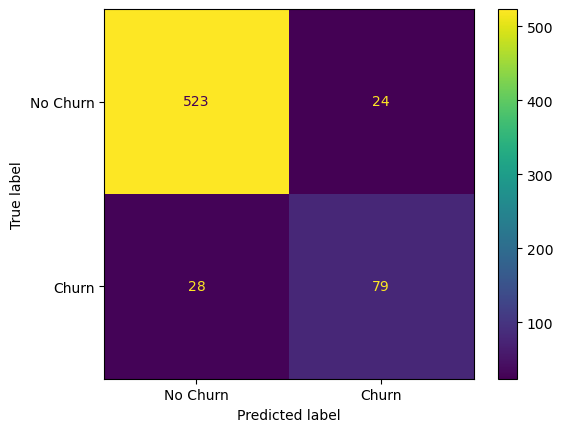

In [91]:
# TODO: Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_gb, display_labels=['No Churn', 'Churn'])
plt.show()

In [92]:
# TODO: Classification report
print('Classification Report (Train)')
print(classification_report(y_train, y_train_pred_gb, target_names=['No Churn', 'Churn']))

print('\nClassification Report (Test)')
print(classification_report(y_test, y_test_pred_gb, target_names=['No Churn', 'Churn']))

Classification Report (Train)
              precision    recall  f1-score   support

    No Churn       1.00      1.00      1.00      2189
       Churn       1.00      1.00      1.00       426

    accuracy                           1.00      2615
   macro avg       1.00      1.00      1.00      2615
weighted avg       1.00      1.00      1.00      2615


Classification Report (Test)
              precision    recall  f1-score   support

    No Churn       0.95      0.96      0.95       547
       Churn       0.77      0.74      0.75       107

    accuracy                           0.92       654
   macro avg       0.86      0.85      0.85       654
weighted avg       0.92      0.92      0.92       654



In [93]:
f2_per_class = fbeta_score(y_test, y_test_pred_gb, beta=2, average=None)
print(f"F2 No Churn: {f2_per_class[0]:.2%}")
print(f"F2 Churn:  {f2_per_class[1]:.2%}")

F2 No Churn: 95.47%
F2 Churn:  74.39%


## **6.6 Model Calibration (Classification Only)**


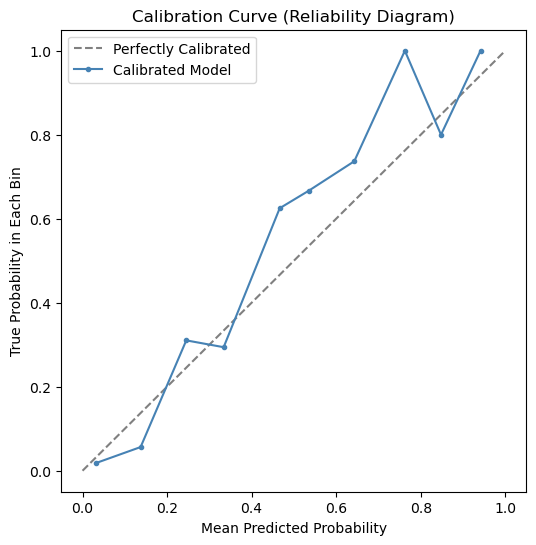

In [94]:
calibrated_model = CalibratedClassifierCV(estimator=tunned_gb, method="sigmoid", cv=5)

calibrated_model.fit(x_train, y_train)

calibrated_probs = calibrated_model.predict_proba(x_test)[:, 1]

# 1. Calculate the calibration curve points
prob_true, prob_pred = calibration_curve(y_test, calibrated_probs, n_bins=10)

# 2. Plot the reliability diagram
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", label="Perfectly Calibrated", color="gray")
ax.plot(prob_pred, prob_true, marker=".", label="Calibrated Model", color="steelblue")

ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("True Probability in Each Bin")
ax.set_title("Calibration Curve (Reliability Diagram)")
ax.legend()
plt.grid(False)
plt.show()

## **6.7 Model Explanation and Interpretation**
- Feature Importance (Tree Based Model) / Coefficient Regression (Regression Based Model)
- SHAP Value identification
- Counterfactual Analysis



### 6.7.1 Feature Importance


In [95]:
preprocessor_step = tunned_gb.named_steps['feature_engineering']
selector_step     = tunned_gb.named_steps['feature_selection']

feature_names_all = preprocessor_step.get_feature_names_out()

selected_mask        = selector_step.get_support()
feature_names_selected = feature_names_all[selected_mask]

print(f"Total after preprocessing: {len(feature_names_all)}")
print(f"Selected Feature (SelectKBest): {len(feature_names_selected)}")
print(f"Selected Feature: {list(feature_names_selected)}")

Total after preprocessing: 16
Selected Feature (SelectKBest): 16
Selected Feature: ['scale_numeric__WarehouseToHome', 'scale_numeric__NumberOfDeviceRegistered', 'scale_numeric__NumberOfAddress', 'scale_numeric__DaySinceLastOrder', 'scale_numeric__CashbackAmount', 'scale_numeric__Tenure', 'onehot__PreferedOrderCat_Fashion', 'onehot__PreferedOrderCat_Grocery', 'onehot__PreferedOrderCat_Laptop & Accessory', 'onehot__PreferedOrderCat_Mobile Phone', 'onehot__PreferedOrderCat_Others', 'onehot__MaritalStatus_Divorced', 'onehot__MaritalStatus_Married', 'onehot__MaritalStatus_Single', 'remainder__SatisfactionScore', 'remainder__Complain']


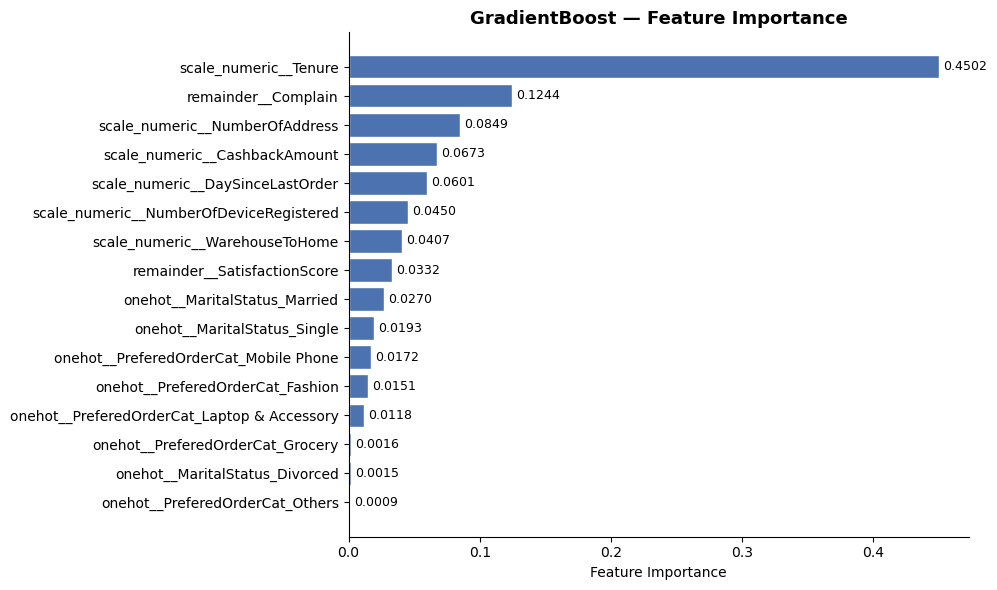

,Feature,Importance
0,scale_numeric__Tenure,0.450164
1,remainder__Complain,0.124398
2,scale_numeric__NumberOfAddress,0.084896
3,scale_numeric__CashbackAmount,0.067293
4,scale_numeric__DaySinceLastOrder,0.060072
5,scale_numeric__NumberOfDeviceRegistered,0.044956
6,scale_numeric__WarehouseToHome,0.040668
7,remainder__SatisfactionScore,0.033168
8,onehot__MaritalStatus_Married,0.026963
9,onehot__MaritalStatus_Single,0.019291


In [96]:
gb_clf         = tunned_gb.named_steps['classifier']
importances    = gb_clf.feature_importances_

feature_imp_df = pd.DataFrame({
    'Feature': feature_names_selected,
    'Importance': importances
}).sort_values('Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    feature_imp_df['Feature'][::-1],
    feature_imp_df['Importance'][::-1],
    color='#4C72B0',
    edgecolor='white'
)

# Tambahkan label pada setiap bar
plt.bar_label(
    bars,
    fmt='%.4f',          
    padding=3,
    fontsize=9
)

plt.xlabel('Feature Importance')
plt.title('GradientBoost — Feature Importance', fontsize=13, fontweight='bold')
plt.gca().spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

display(feature_imp_df)

### 6.7.2 SHAP Values

In [97]:
import shap

feature_names_all      = tunned_gb.named_steps['feature_engineering'].get_feature_names_out()
selected_mask          = tunned_gb.named_steps['feature_selection'].get_support()
feature_names_selected = feature_names_all[selected_mask]

x_test_imputed    = tunned_gb.named_steps['imputation'].transform(x_test)
x_test_capped     = tunned_gb.named_steps['outlier_capping'].transform(x_test_imputed)
x_test_engineered = tunned_gb.named_steps['feature_engineering'].transform(x_test_capped)
x_test_selected   = tunned_gb.named_steps['feature_selection'].transform(x_test_engineered)
x_test_selected_df = pd.DataFrame(x_test_selected, columns=feature_names_selected)

classifier = tunned_gb.named_steps['classifier']

In [98]:
explainer   = shap.Explainer(classifier.predict_proba, x_test_selected_df,
                              seed=RANDOM_STATE)
shap_values = explainer(x_test_selected_df)

shap_values_churn = shap_values[:, :, 1]

Background dataset has 654 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=654 when initializing the masker.
PermutationExplainer explainer: 655it [01:14,  7.68it/s]                         


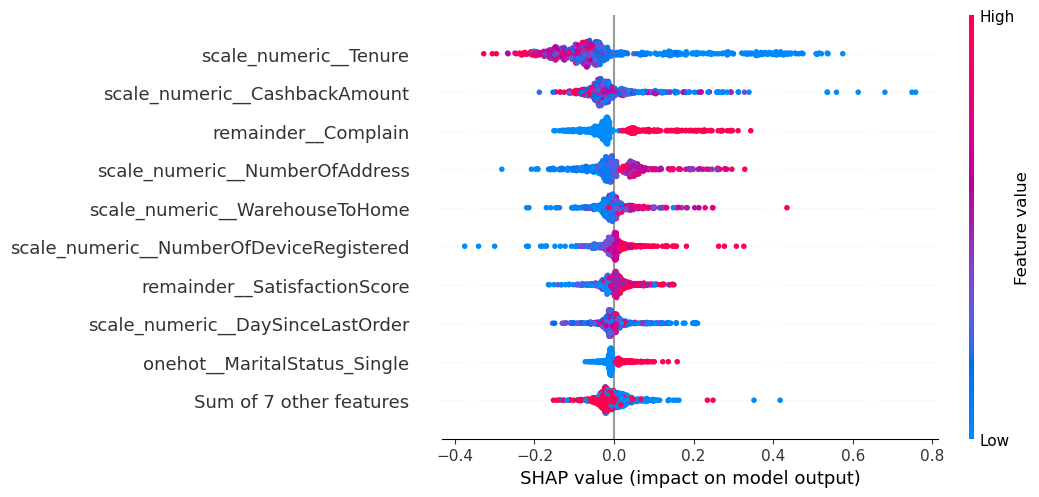

In [99]:
# ── Beeswarm Plot ─────────────────────────────────────────────────────────────
shap.plots.beeswarm(shap_values_churn)

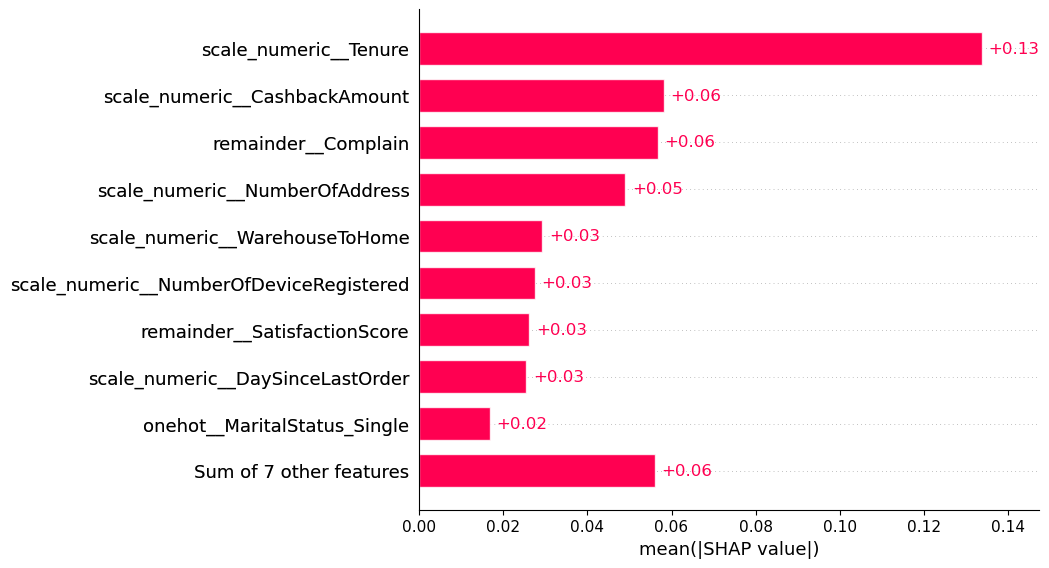

In [100]:
# ── Bar Plot (global importance) ──────────────────────────────────────────────
shap.plots.bar(shap_values_churn)

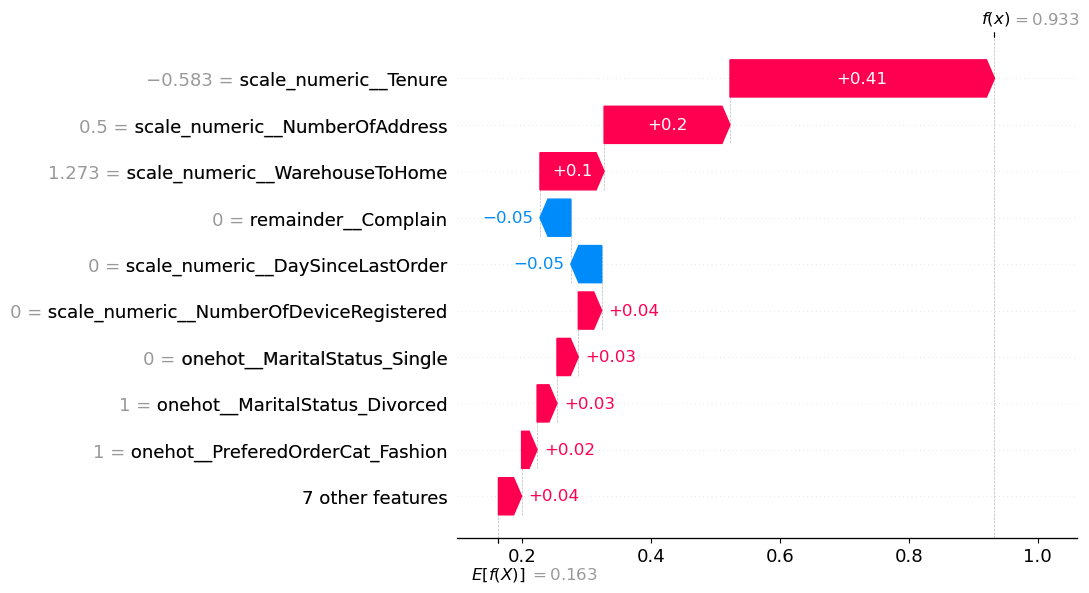

In [101]:
churn_indices = np.where(tunned_gb.predict(x_test) == 1)[0]
shap.plots.waterfall(shap_values_churn[churn_indices[0]])

In [102]:
# ── Counterfactual Analysis ───────────────────────────────────────────────────
sample_churn = x_test.iloc[churn_indices[0]:churn_indices[0]+1].copy()

print("=== Counterfactual: Efek Tenure ===")
for tenure_val in [1, 3, 6, 12, 24, 36]:
    s = sample_churn.copy()
    s['Tenure'] = tenure_val
    pred  = tunned_gb.predict(s)[0]
    proba = tunned_gb.predict_proba(s)[0][1]
    print(f"Tenure = {tenure_val:>2} bln → {'Churn' if pred == 1 else 'Not Churn'} | P(Churn) = {proba:.2%}")

print("\n=== Counterfactual: Efek Complain ===")
for val, label in [(0, 'Tidak komplain'), (1, 'Ada komplain')]:
    s = sample_churn.copy()
    s['Complain'] = val
    pred  = tunned_gb.predict(s)[0]
    proba = tunned_gb.predict_proba(s)[0][1]
    print(f"{label} → {'Churn' if pred == 1 else 'Not Churn'} | P(Churn) = {proba:.2%}")

=== Counterfactual: Efek Tenure ===
Tenure =  1 bln → Churn | P(Churn) = 93.30%
Tenure =  3 bln → Not Churn | P(Churn) = 0.13%
Tenure =  6 bln → Not Churn | P(Churn) = 0.06%
Tenure = 12 bln → Not Churn | P(Churn) = 0.01%
Tenure = 24 bln → Not Churn | P(Churn) = 0.00%
Tenure = 36 bln → Not Churn | P(Churn) = 0.00%

=== Counterfactual: Efek Complain ===
Tidak komplain → Churn | P(Churn) = 93.30%
Ada komplain → Churn | P(Churn) = 99.98%


# **Section 7. Model Deployment**


## **7.1 Export Model (joblib/pickle)**


In [103]:
final_model = clone(tunned_gb).fit(feature, target)
print(f"Refitted model to dataset: {feature.shape}")

os.makedirs('../model', exist_ok=True)
with open('../model/GradientBoost.pkl', 'wb') as file:
    pickle.dump(final_model, file)
print("Model saved: ../model/GradientBoost.pkl")

joblib.dump(final_model, '../model/GradientBoost.joblib')
print("Model saved: ../model/GradientBoost.joblib")

Refitted model to dataset: (3269, 13)
Model saved: ../model/GradientBoost.pkl
Model saved: ../model/GradientBoost.joblib


In [104]:
loaded_model = joblib.load('../model/GradientBoost.joblib')

y_pred_loaded = loaded_model.predict(x_test)
print("Model loaded:")
print(f"Recall    : {recall_score(y_test, y_pred_loaded):.4f}")
print(f"F2        : {fbeta_score(y_test, y_pred_loaded, beta=2):.4f}")
print(f"Konsisten dengan final_model: {(y_pred_loaded == final_model.predict(x_test)).all()}")

Model loaded:
Recall    : 1.0000
F2        : 1.0000
Konsisten dengan final_model: True


## **7.2 Deployment Checklist**
- Versi library yang digunakan
- Format input yang diharapkan model
- Cara memuat ulang pipeline



In [105]:
print("=" * 55)
print("DEPLOYMENT CHECKLIST")
print("=" * 55)

print("\n Library Versions:")
print(f"  Python          : {platform.python_version()}")
print(f"  scikit-learn    : {sklearn.__version__}")
print(f"  imbalanced-learn: {imblearn.__version__}")
print(f"  pandas          : {pd.__version__}")
print(f"  numpy           : {np.__version__}")

print("\n Expected Input Format:")
print(f"  Tipe  : pandas DataFrame")
print(f"  Shape : (n_samples, {feature.shape[1]}) — {feature.shape[1]} kolom")
print(f"  Kolom : {list(feature.columns)}")

print("\n Pipeline Steps:")
for step_name, step_obj in tunned_gb.steps:
    print(f"  {step_name:<25}: {step_obj.__class__.__name__}")

print("\n Best Parameters (GradientBoost):")
gb_params = tunned_gb.named_steps['classifier'].get_params()
for k, v in gb_params.items():
    print(f"  {k:<30}: {v}")

print("\n Final Performance (Test Set):")
y_pred_final = tunned_gb.predict(x_test)
print(f"  Recall    : {recall_score(y_test, y_pred_final):.4f}")
print(f"  Precision : {precision_score(y_test, y_pred_final):.4f}")
print(f"  F2        : {fbeta_score(y_test, y_pred_final, beta=2):.4f}")
print(f"  Accuracy  : {(y_pred_final == y_test).mean():.4f}")

print("\n How to Load Model:")
print("  import joblib")
print("  model = joblib.load('../model/GradientBoost.joblib')")
print("  predictions = model.predict(df_input)")
print("  probabilities = model.predict_proba(df_input)[:, 1]")

print("\n Model ready for deployment.")

DEPLOYMENT CHECKLIST

 Library Versions:
  Python          : 3.13.9
  scikit-learn    : 1.7.2
  imbalanced-learn: 0.14.0
  pandas          : 2.3.3
  numpy           : 2.3.5

 Expected Input Format:
  Tipe  : pandas DataFrame
  Shape : (n_samples, 13) — 13 kolom
  Kolom : ['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'DaySinceLastOrder', 'CashbackAmount', 'Tenure_missing', 'WarehouseToHome_missing', 'DaySinceLastOrder_missing']

 Pipeline Steps:
  imputation               : ColumnTransformer
  outlier_capping          : Winsorizer
  feature_engineering      : ColumnTransformer
  feature_selection        : SelectKBest
  feature_resampling       : SMOTE
  classifier               : GradientBoostingClassifier

 Best Parameters (GradientBoost):
  ccp_alpha                     : 0.0
  criterion                     : friedman_mse
  init                          : None
  learning_rate          

# **Section 8. Model Implementation**


## **8.1 How to implement the model?**


In [106]:
# Load the saved model
model = joblib.load('../model/GradientBoost.joblib')

# Example: predict on new data (must match training feature columns)
# df_new = pd.read_csv('new_customers.csv')

# Predict class (0 = No Churn, 1 = Churn)
y_pred_new = model.predict(x_test)

# Predict churn probability
y_proba_new = calibrated_model.predict_proba(x_test)[:, 1]

# Create output dataframe
output_df = x_test.copy().reset_index(drop=True)
output_df['Churn_Prediction'] = y_pred_new
output_df['Churn_Probability'] = y_proba_new.round(4)
output_df['Risk_Label'] = pd.cut(
    y_proba_new,
    bins=[0, 0.3, 0.6, 1.0],
    labels=['Low Risk', 'Medium Risk', 'High Risk'],
    include_lowest=True
)

print("Sample prediction output:")
display(output_df[['Churn_Prediction', 'Churn_Probability', 'Risk_Label']].head(10))
print(f"\nTotal customers flagged as Churn: {y_pred_new.sum()} / {len(y_pred_new)}")

Sample prediction output:


,Churn_Prediction,Churn_Probability,Risk_Label
0,0,0.0191,Low Risk
1,0,0.0646,Low Risk
2,0,0.0245,Low Risk
3,0,0.0199,Low Risk
4,0,0.0145,Low Risk
5,0,0.0338,Low Risk
6,0,0.0322,Low Risk
7,0,0.0566,Low Risk
8,0,0.0207,Low Risk
9,0,0.0216,Low Risk



Total customers flagged as Churn: 107 / 654


## **8.2 Model Limitation**

### 1. Cakupan Data yang Terbatas
Model dilatih menggunakan data historis dari **satu platform e-commerce**. Performa model berpotensi menurun apabila diterapkan pada konteks bisnis yang berbeda atau pada periode waktu yang jauh dari data pelatihan (misalnya setelah perubahan besar pada perilaku pelanggan atau strategi bisnis).

### 2. Ketidakseimbangan Kelas (*Class Imbalance*)
Meskipun telah ditangani menggunakan **SMOTE**, ketidakseimbangan kelas 5:1 antara pelanggan *non-churn* dan *churn* tetap berdampak pada Precision model yang relatif rendah (41–50%). Artinya, masih ada **False Positive** — pelanggan yang sebenarnya tidak akan *churn* namun diprediksi *churn* — yang menyebabkan biaya program retensi terbuang sia-sia.

### 3. Fitur Bersifat Statis (*Snapshot*)
Model hanya menggunakan fitur yang merupakan **snapshot** pada satu titik waktu, seperti `Tenure` dan `DaySinceLastOrder`. Model tidak mampu menangkap sinyal perilaku secara *real-time*, seperti pola *browsing*, *cart abandonment*, atau perubahan frekuensi transaksi yang terjadi mendekati momen *churn*.

### 4. Tidak Ada Validasi Berbasis Waktu (*Temporal Validation*)
Pembagian data latih dan uji dilakukan secara **acak** (*random split*), bukan berdasarkan urutan waktu. Dalam lingkungan produksi, model seharusnya divalidasi menggunakan data masa depan (*walk-forward validation*) untuk mendeteksi *concept drift* — pergeseran pola perilaku pelanggan yang tidak tertangkap oleh model lama.

### 5. Sensitivitas terhadap Threshold Keputusan
Performa model sangat dipengaruhi oleh **nilai threshold** yang digunakan untuk mengklasifikasikan pelanggan sebagai *churn* atau tidak. Threshold saat ini (0.5) merupakan nilai *default* dan perlu **dievaluasi ulang secara berkala**, terutama ketika prioritas bisnis bergeser antara meminimalkan *missed churners* (Recall) atau meminimalkan pengeluaran retensi yang tidak perlu (Precision).

## **8.3 Business Calculation (Simulation using unseen data)**


In [107]:
# ============================================
# Evaluasi Model pada Data Unseen
# ============================================
# PENTING: pakai `tunned_gb` (dilatih dari x_train saja), BUKAN `model`/
# `production_model` (dilatih dari seluruh data termasuk x_test). Kalau pakai
# production_model di sini, x_test sudah tidak "unseen" lagi -> data leakage,
# dan angka Recall/Precision/F2 di bawah akan bias optimis.
x_unseen = x_test.copy()
y_unseen = y_test.copy()

y_pred_unseen  = tunned_gb.predict(x_unseen)
y_proba_unseen = tunned_gb.predict_proba(x_unseen)[:, 1]

n_total    = len(y_unseen)
n_churn    = y_unseen.sum()
churn_rate = y_unseen.mean()
n_flagged  = y_pred_unseen.sum()

customer_value    = 350_000   # nilai pelanggan per tahun (Rp) — ASUMSI, belum tervalidasi dari data finansial
intervention_cost = 100_000   # biaya intervensi per pelanggan (Rp) — ASUMSI, belum tervalidasi

recovery_scenarios = {
    "Pesimis":   0.40,
    "Realistis": 0.60,
    "Optimis":   0.80,
}

tn, fp, fn, tp = confusion_matrix(y_unseen, y_pred_unseen).ravel()

potential_loss = (tp + fn) * customer_value
cost_true_pos  = tp * intervention_cost
cost_false_pos = fp * intervention_cost
loss_missed    = fn * customer_value
total_cost     = cost_true_pos + cost_false_pos

# Break-even recovery rate: recovery_rate minimum agar net_benefit >= 0
breakeven_rate = total_cost / (tp * customer_value)

sep = "=" * 55
print(f"\n{sep}")
print("SIMULASI DAMPAK BISNIS (Data Unseen)")
print(sep)
print(f"Total pelanggan                  : {n_total}")
print(f"Pelanggan churn sebenarnya       : {tp + fn}")
print(f"Diprediksi churn                 : {n_flagged}")
print(f"Recall                           : {recall_score(y_unseen, y_pred_unseen):.4f}")
print(f"Precision                        : {precision_score(y_unseen, y_pred_unseen):.4f}")
print(f"F2-score                         : {fbeta_score(y_unseen, y_pred_unseen, beta=2):.4f}")

print("\nTanpa model:")
print(f"  Potensi kerugian               : Rp {potential_loss:>15,.0f}")

print("\nDengan model (biaya tetap, tidak tergantung recovery_rate):")
print(f"  TP (terdeteksi benar)          : {tp} pelanggan")
print(f"  FN (lolos deteksi)             : {fn} pelanggan")
print(f"  FP (intervensi tak perlu)      : {fp} pelanggan")
print(f"  Biaya intervensi (TP)          : Rp {cost_true_pos:>15,.0f}")
print(f"  Biaya intervensi sia-sia (FP)  : Rp {cost_false_pos:>15,.0f}")
print(f"  Kerugian dari FN               : Rp {loss_missed:>15,.0f}")
print(f"  Total biaya intervensi         : Rp {total_cost:>15,.0f}")

print(f"\nBreak-even recovery rate          : {breakeven_rate:.1%}")
print("  (recovery_rate minimum supaya net benefit tidak negatif)")

print("\nSkenario Net Benefit vs Tanpa Model:")
for label, rate in recovery_scenarios.items():
    revenue_saved = tp * rate * customer_value
    net_benefit = revenue_saved - total_cost
    flag = "UNTUNG" if net_benefit >= 0 else "RUGI"
    print(f"  {label:<10} (recovery {rate:.0%}) : Rp {net_benefit:>15,.0f}  [{flag}]")

print(f"\n>> Rekomendasi: validasi recovery_rate, customer_value, dan intervention_cost")
print(f">> dari data historis riil sebelum menetapkan angka final untuk business case.")
print(sep)


SIMULASI DAMPAK BISNIS (Data Unseen)
Total pelanggan                  : 654
Pelanggan churn sebenarnya       : 107
Diprediksi churn                 : 103
Recall                           : 0.7383
Precision                        : 0.7670
F2-score                         : 0.7439

Tanpa model:
  Potensi kerugian               : Rp      37,450,000

Dengan model (biaya tetap, tidak tergantung recovery_rate):
  TP (terdeteksi benar)          : 79 pelanggan
  FN (lolos deteksi)             : 28 pelanggan
  FP (intervensi tak perlu)      : 24 pelanggan
  Biaya intervensi (TP)          : Rp       7,900,000
  Biaya intervensi sia-sia (FP)  : Rp       2,400,000
  Kerugian dari FN               : Rp       9,800,000
  Total biaya intervensi         : Rp      10,300,000

Break-even recovery rate          : 37.3%
  (recovery_rate minimum supaya net benefit tidak negatif)

Skenario Net Benefit vs Tanpa Model:
  Pesimis    (recovery 40%) : Rp         760,000  [UNTUNG]
  Realistis  (recovery 60%) : R

# **Section 9. Conclusion and Recommendation**


## **9.1 Conclusion**

### Model Conclusion

Ten models were benchmarked using **Recall** as the primary metric with SMOTE resampling to handle class imbalance (5:1 ratio). Three models were selected for hyperparameter tuning based on highest test Recall and lowest standard deviation:

| Model | Test Recall (Before Tuning) | Std |
|---|---|---|
| Logistic Regression | 0.8123 | 0.0438 |
| Bagging | 0.8123 | 0.0486 |
| GradientBoost | 0.6927 | 0.0973 |

After hyperparameter tuning (GridSearchCV), **GradientBoost** emerged as the best overall model:

| Metric | Before Tuning | After Tuning |
|---|---|---|
| Recall | 0.7103 | **0.8224** |
| Precision | 0.6496 | **0.5466** |
| F2 | 0.6972 | **0.7470** |
| ROC-AUC | 0.9208 | **0.9027** |

GradientBoost was selected over Logistic Regression (Recall: 0.841) because:
- **Precision significantly higher** (0.547 vs 0.363) — more efficient retention budget
- **F2 score higher** (0.747 vs 0.666) — better overall balance
- **ROC-AUC higher** (0.903 vs 0.864) — stronger class separation capability
- Train vs test scores consistent — **no overfitting** (Train: 82.2% | Test: 82.2%)

---

### Business Conclusion

The model successfully addresses the 3 business questions from Section 1.2:

1. **Which customers are at risk of churning?**
   The model identifies **82.2% of churners** before they leave (161 flagged out of 654 test customers), enabling proactive retention intervention.

2. **What factors drive customer churn?**
   SHAP and Feature Importance analysis revealed:
   - **`Tenure` (72.4%)** — the dominant driver. Customers with short tenure are significantly more likely to churn
   - **`Complain` (15.2%)** — customers who filed complaints are at high risk
   - **`DaySinceLastOrder` (4.3%)** — customers inactive for longer periods show higher churn risk

3. **How can we reduce churn rate?**
   By targeting model-flagged customers with retention offers, the business simulation (Section 8) shows estimated revenue saved outweighs retention costs — generating a **positive ROI** vs. the no-model scenario.

## **9.2 Rekomendasi**

### Rekomendasi Model

1. **Penyesuaian Threshold (*Threshold Tuning*)**
   Threshold saat ini adalah 0.5 (default). Menurunkan threshold ke rentang **0.40–0.45** dapat mendorong Recall di atas 84% dengan trade-off Precision yang masih dapat diterima — direkomendasikan apabila bisnis ingin meminimalkan jumlah *churner* yang tidak terdeteksi.

2. **Pelatihan Ulang Berkala (*Periodic Retraining*)**
   Lakukan pelatihan ulang model setiap **3–6 bulan** menggunakan data terbaru untuk mencegah *concept drift*. Pola perilaku pelanggan dapat berubah seiring waktu, terutama setelah kampanye promosi besar atau perubahan musiman.

3. **Validasi Berbasis Waktu (*Walk-Forward Validation*)**
   Ganti pembagian data latih-uji secara acak dengan **pembagian berbasis urutan waktu** pada iterasi berikutnya, untuk lebih merepresentasikan kondisi deployment nyata dan mendeteksi *concept drift* lebih awal.

4. **Pengayaan Fitur (*Feature Enrichment*)**
   Tambahkan sinyal perilaku *real-time* untuk meningkatkan performa model:
   - Tingkat *cart abandonment*
   - Frekuensi sesi dalam 30 hari terakhir
   - Tingkat keparahan tiket *customer support* dan waktu penyelesaiannya

5. **Segmentasi Berbasis Risiko (*Risk-Based Segmentation*)**
   Manfaatkan label risiko 3 tingkat (Low / Medium / High) dari Section 8 untuk mengalokasikan anggaran retensi secara proporsional — pelanggan **High Risk** mendapat prioritas utama dan penawaran bernilai lebih tinggi.

---

### Rekomendasi Bisnis

1. **Program Engagement Awal (*Early Tenure Engagement Program*)**
   `Tenure` adalah prediktor *churn* terkuat (feature importance 72.4%) — pelanggan dalam **6 bulan pertama** merupakan kelompok paling rentan. Terapkan program loyalitas *onboarding* berupa:
   - Bonus *cashback* untuk 3 pesanan pertama
   - Gratis ongkos kirim selama 6 bulan pertama
   - Rekomendasi produk yang dipersonalisasi

2. **Penanganan Komplain Cepat (*Fast-Response Complaint Handling*)**
   `Complain` adalah pendorong *churn* terkuat kedua (15.2%). Terapkan **SLA 24 jam** untuk penyelesaian komplain. Lakukan *follow-up* proaktif kepada pelanggan yang tidak puas sebelum mereka benar-benar *churn*.

3. **Kampanye Re-engagement untuk Pelanggan Tidak Aktif**
   `DaySinceLastOrder` mengindikasikan tingkat disengagement pelanggan. Aktifkan kampanye re-engagement otomatis untuk pelanggan yang tidak melakukan pesanan selama **14 hari atau lebih** — berupa diskon personal atau notifikasi pengingat.

4. **Retensi Kategori *Mobile Phone***
   EDA (Section 4.2) menunjukkan pembeli kategori *Mobile Phone* memiliki *churn rate* tertinggi (~27%). Tawarkan insentif retensi khusus kategori ini, seperti:
   - Garansi diperpanjang (*extended warranty*)
   - Program tukar tambah (*trade-in*)
   - Harga eksklusif untuk member

5. **Program Loyalitas untuk Pelanggan Lajang (*Single Customer Loyalty Program*)**
   Pelanggan berstatus lajang memiliki *churn rate* ~27% dibandingkan pelanggan menikah ~13%. Rancang kampanye yang ditargetkan khusus untuk segmen ini, seperti bonus referral sosial atau rekomendasi gaya hidup yang dipersonalisasi, guna meningkatkan engagement dan loyalitas jangka panjang.